# Research question

This study examines how compact models compare with the saved Gemma baseline when identifying OTC medicines from supplied FDA and RxNorm evidence. This notebook trains XGBoost from scratch and keeps the final 230 cases out of development.

The fixed benchmark was inspected during earlier Gemma development. Results describe agreement with source records and the output contract, rather than independent clinical knowledge.


# 1. Environment and inputs

Use the repository Python environment. The current configuration uses the full training dataset. A smaller smoke test can be enabled separately to check the implementation before training.


## 1.1 Import standard libraries

These imports cover local paths, file formats, timing and reproducibility. Model packages are checked before they are imported.


In [7]:
from IPython.display import display
from pathlib import Path
import csv
import gzip
import hashlib
import importlib.metadata as metadata
import importlib.util
import inspect
import json
import os
import random
import shutil
import sys
import time
import uuid
from collections import Counter, defaultdict
from datetime import datetime, timezone


## 1.2 Configure the run

To continue, set `RESUME_RUN` to the full experiment directory and Run All with the same seed and training settings. Compatibility or checksum failures stop the run. Completed heads are retained; an interrupted fit restarts only that head. Runs created before resume manifests were introduced cannot be resumed.

The repository is resolved from the current folder. Each run writes to a new output directory so earlier results remain available.


In [49]:
SEED = 42
SMOKE_TEST = False
RUN_FULL_TRAINING = True
PREPARE_DATA = True
# Full path of an existing compatible experiment; None starts a new run
RESUME_RUN = None
EXPORT_BUNDLE = True
RUN_FINAL_CHALLENGE_EVAL = False
MODEL_SETTINGS_FROZEN = False
# Set this only to score predictions copied back from Colab
SET_PREDICTIONS = None
SET_FREEZE_FILE = None
SET_RAW_DECISIONS = None

def find_repo():
    for path in (Path.cwd(), *Path.cwd().parents):
        for root in (path, path / "otc-medication-llm-reliability"):
            if (root / "src/hrp/challenge_evaluation.py").is_file():
                return root.resolve()
    raise FileNotFoundError("Open this notebook from the repository or its notebooks folder")

ROOT = find_repo()
RAW_ROOT = ROOT.parent / "data"
GEMMA_ROOT = ROOT.parent / "runpod-backups/stage06-audit/results/stage06_challenge_v1_original_gemma4"
SNAPSHOT_ROOT = ROOT.parent / "runpod-backups/stage06-audit/repo"
CHALLENGE_ROOT = ROOT / "results/challenge_v1"
if RESUME_RUN is None:
    run_name = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
    RUN_ROOT = ROOT / "results/otc_models" / ("xgboost_" + run_name)
    RUN_ROOT.mkdir(parents=True, exist_ok=False)
else:
    RUN_ROOT = Path(RESUME_RUN).expanduser().resolve()
    if not RUN_ROOT.is_dir() or not (RUN_ROOT / "resume_manifest.json").is_file():
        raise ValueError("Resume requires an existing run with resume_manifest.json")
BUNDLE_ROOT = RUN_ROOT / "prepared_data"
BUNDLE_ROOT.mkdir(exist_ok=True)
csv.field_size_limit(32 * 1024 * 1024)
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "tools")]


## 1.3 Check package versions

Install any missing packages in the selected kernel environment and restart the kernel before continuing.


In [66]:
import copy
import csv
import gzip
import hashlib
import json
import os
import uuid
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

from hrp import challenge_evaluation as contract
from hrp.challenge_scoring_v3 import score_predictions
from hrp.data_cleaning import normalize_name, quantity_key, route_signature


In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jsonschema
import xgboost as xgb

In [51]:
required = ["numpy", "pandas", "xgboost", "scikit-learn", "matplotlib",
            "nbformat", "jsonschema", "ijson", "rapidfuzz"]
missing = []
print("Python", sys.version)
for name in required:
    try:
        print(name, metadata.version(name))
    except metadata.PackageNotFoundError:
        missing.append(name)
if missing:
    print("Install in the notebook kernel environment")
    print(str(sys.executable) + " -m pip install " + " ".join(missing))
    raise ImportError("Install the listed packages and restart the kernel")


Python 3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]
numpy 2.5.4
pandas 3.1.1
xgboost 3.4.1
scikit-learn 1.9.1
matplotlib 3.11.2
nbformat 5.11.1
jsonschema 4.26.0
ijson 3.6.0
rapidfuzz 3.14.3


## 1.4 Check required files

The preflight uses a closed list of local inputs. Saved retrieval predictions are inspected as existing artifacts and never become predictor features.


In [53]:
from hrp import challenge_evaluation as contract
from hrp.challenge_scoring_v3 import score_predictions, SCORING_CONTRACT_VERSION
from hrp.data_cleaning import normalize_name, quantity_key, route_signature
from hrp.retrieval_baseline import load_catalog, retrieve_evidence
import build_challenge_v1 as builder

In [54]:
# Only read the source helper functions and never call the frozen dataset builder
required_files = [
    "data/processed/final_v5/train.csv", "data/processed/final_v5/validation.csv",
    "data/processed/final_v5/family_split_manifest.csv",
    "data/processed/final_v5/train_retrieval_predictions.jsonl",
    "data/processed/final_v5/validation_retrieval_predictions.jsonl",
    "data/interim/final_v5/catalog_evidence.csv",
    "data/interim/final_v5/otc_catalog_consistent.csv",
    "data/interim/final_v5/fda_ingredient_identifiers.csv",
    "data/interim/final_v5/otc_ndc_label_links.csv",
    "data/interim/final_v5/otc_rxnorm_ingredient_links.csv",
    "data/interim/final_v5/otc_rxnorm_product_links.csv",
    "results/challenge_v1/benchmark.PRIVATE.jsonl",
    "results/challenge_v1/common_evidence.PRIVATE.jsonl",
    "results/challenge_v1/ingredient_identity_mapping.PRIVATE.jsonl",
    "results/challenge_v1/training_allowlist.PRIVATE.csv",
    "results/challenge_v1/training_quarantine.PRIVATE.jsonl",
    "results/challenge_v1/output_schema.json",
    "results/challenge_v1/scoring_specifications.json",
    "results/challenge_v1/freeze_manifest.json",
    "results/challenge_v1/selection_policy.json",
    "results/challenge_v1_scoring_amendment/verification_report.json",
    "results/challenge_v1_scoring_amendment/scoring_amendment_manifest.json",
    "src/hrp/benchmark.py", "src/hrp/retrieval_baseline.py",
    "src/hrp/challenge_evaluation.py", "src/hrp/challenge_scoring_v3.py",
    "src/hrp/evidence_adapter.py", "src/hrp/data_cleaning.py",
    "tools/build_challenge_v1.py", "tools/revised_scope_validation_audit.py",
    "pyproject.toml"
]


In [55]:
missing = [name for name in required_files if not (ROOT / name).is_file()]
if missing:
    raise FileNotFoundError("Missing local inputs\n" + "\n".join(missing))
for name in ("aggregate.json", "factual_validation_metrics.json",
             "validated_outputs.PRIVATE.jsonl", "case_diagnostics.PRIVATE.jsonl"):
    if not (GEMMA_ROOT / name).is_file():
        raise FileNotFoundError(GEMMA_ROOT / name)

## 1.5 Verify the source and scorer snapshot

The archived Stage 6 files are local backups. Source extraction and scoring must agree with that snapshot before preparation starts.


In [56]:
# Check archived schemas without passing archived predictions to any model
for name in ("aggregate.json", "factual_validation_metrics.json"):
    value = json.loads((GEMMA_ROOT / name).read_text(encoding="utf-8"))
    print("Archive schema", name, list(value))
for name in ("validated_outputs.PRIVATE.jsonl", "case_diagnostics.PRIVATE.jsonl"):
    with (GEMMA_ROOT / name).open(encoding="utf-8") as stream:
        print("Archive row schema", name, list(json.loads(next(stream))))
for name in ("challenge_evaluation.py", "challenge_scoring_v3.py", "data_cleaning.py"):
    local = (ROOT / "src/hrp" / name).read_text(encoding="utf-8")
    saved = (SNAPSHOT_ROOT / "src/hrp" / name).read_text(encoding="utf-8")
    if local != saved:
        raise RuntimeError("Stage 6 source differs after newline normalization " + name)
print("Scoring contract", SCORING_CONTRACT_VERSION)


Archive schema aggregate.json ['configuration', 'model_load_attempts', 'requested_cases', 'pending_requested_cases', 'attempted_cases', 'completed_cases', 'valid_json_cases', 'valid_schema_cases', 'valid_contract_cases', 'failure_categories', 'stop_reasons', 'generation_latency_seconds', 'generation_gpu_memory', 'updated_at_utc', 'raw_strict_json_valid_cases', 'normalized_json_valid_cases', 'normalized_schema_valid_cases', 'fence_removed_cases']
Archive schema factual_validation_metrics.json ['configuration', 'primary_role', 'supplementary_role', 'retrieval_replay_sha256', 'private_input_sha256', 'prediction_ledger_sha256', 'inference_aggregate_sha256', 'model_load_attempts', 'models']
Archive row schema validated_outputs.PRIVATE.jsonl ['case_id', 'output']
Archive row schema case_diagnostics.PRIVATE.jsonl ['case_id', 'family_groups', 'role', 'category', 'models']
Scoring contract challenge_v1_scoring_contract_3


In [57]:
# These files are inspected only for schema and never become evidence inputs
for name in required_files:
    path = ROOT / name
    if path.suffix == ".csv":
        with path.open(encoding="utf-8-sig", newline="") as stream:
            print(name, next(csv.reader(stream)))
label_archives = builder.prior.source_archives(RAW_ROOT, "label")
ndc_archives = builder.prior.source_archives(RAW_ROOT, "ndc")
rx_files = sorted((RAW_ROOT / "raw/rxnorm").glob("*/rrf/RXNCONSO.RRF"))
if len(rx_files) != 1 or not rx_files[0].with_name("RXNREL.RRF").is_file():
    raise FileNotFoundError("One full local RxNorm release with RXNCONSO and RXNREL is required")
if len(label_archives) != 14 or len(ndc_archives) != 1:
    raise RuntimeError("The original FDA source archive inventory has changed")

data/processed/final_v5/train.csv ['case_id', 'partition', 'task', 'case_type', 'input_json', 'reference_json', 'family_group_ids_json', 'provenance_json']
data/processed/final_v5/validation.csv ['case_id', 'partition', 'task', 'case_type', 'input_json', 'reference_json', 'family_group_ids_json', 'provenance_json']
data/processed/final_v5/family_split_manifest.csv ['product_ndc', 'family_group_id', 'partition', 'ingredient_eligible', 'formulation_eligible', 'support_tier']
data/interim/final_v5/catalog_evidence.csv ['source_row', 'product_ndc', 'brand_name', 'generic_name', 'display_name', 'normalized_name', 'name_source', 'dosage_form', 'route', 'marketing_category', 'active_ingredients_json', 'source_rows', 'original_ingredients_json', 'label_extracted_ingredients_json', 'ingredient_origin', 'ingredient_eligible', 'formulation_eligible', 'support_tier', 'rxnorm_name_agreement', 'rxnorm_product_rxcui', 'rxnorm_in_rxcuis_json', 'rxnorm_pin_rxcuis_json', 'rxnorm_identity_options_json', 

# 2. Training and development splits

The approved source contains 75,372 training cases. Excluding every challenge family leaves 12,354 development cases from the original 15,393. Family components divide development into early stopping and calibration sets.


## 2.1 Read permitted membership fields

Only challenge IDs and family membership are retained for exclusions. Reference values do not enter the training or development records.


In [58]:
import ijson

In [59]:
def csv_rows(path):
    with Path(path).open(encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))

def challenge_membership(path):
    # Keep only IDs and family names while skipping all reference values
    records, current = [], {}
    with Path(path).open("rb") as stream:
        for prefix, event, value in ijson.parse(stream, multiple_values=True):
            if prefix == "" and event == "start_map":
                current = {"families": []}
            elif prefix == "case_id" and event == "string":
                current["case_id"] = value
            elif prefix == "families.item" and event == "string":
                current["families"].append(value)
            elif prefix == "" and event == "end_map":
                records.append(current)
    return records


## 2.2 Apply the allowlist and quarantine

Training must account for every allowlisted case. Development removes the 230 fixed cases and all other cases in their 153 families.


In [60]:
members = challenge_membership(CHALLENGE_ROOT / "benchmark.PRIVATE.jsonl")
challenge_ids = {r["case_id"] for r in members}
challenge_groups = {g for r in members for g in r["families"]}
allow_rows = csv_rows(CHALLENGE_ROOT / "training_allowlist.PRIVATE.csv")
allowed = {r["case_id"] for r in allow_rows}
with (CHALLENGE_ROOT / "training_quarantine.PRIVATE.jsonl").open(encoding="utf-8") as stream:
    quarantine = json.loads(next(stream))
blocked = set(quarantine["blocked_training_groups"])
if len(members) != 230 or len(challenge_ids) != 230 or len(challenge_groups) != 153:
    raise RuntimeError("Unexpected frozen challenge inventory")
if len(allow_rows) != 75372 or len(allowed) != 75372:
    raise RuntimeError("Unexpected training allowlist")

raw_train = csv_rows(ROOT / "data/processed/final_v5/train.csv")
raw_dev = csv_rows(ROOT / "data/processed/final_v5/validation.csv")
train_rows = [r for r in raw_train if r["case_id"] in allowed]
dev_rows = [r for r in raw_dev if r["case_id"] not in challenge_ids
            and not challenge_groups.intersection(json.loads(r["family_group_ids_json"]))]
if len(raw_train) != 81251 or len(raw_dev) != 15393:
    raise RuntimeError("Unexpected original case counts")
if {r["case_id"] for r in train_rows} != allowed or len(train_rows) != 75372:
    raise RuntimeError("Training allowlist not fully accounted for")
if len(dev_rows) != 12354:
    raise RuntimeError("Development exclusions changed")
allow_groups = {r["case_id"]: json.loads(r["family_group_ids_json"]) for r in allow_rows}
for row in train_rows:
    if row["partition"] != "train":
        raise ValueError("Nontraining row in training")
    groups = set(json.loads(row["family_group_ids_json"]))
    if groups & (blocked | challenge_groups):
        raise ValueError("Quarantined family reached training")
    if groups != set(allow_groups[row["case_id"]]):
        raise ValueError("Allowlist family metadata differs")
if any(r["partition"] != "validation" for r in dev_rows):
    raise ValueError("Unexpected development partition")


## 2.3 Check family and semantic isolation

Compare normalized inputs as well as family IDs. The source payload is used only to detect final-query overlap.


In [61]:
def group_set(rows):
    return {g for row in rows for g in json.loads(row["family_group_ids_json"])}

def input_set(rows):
    return {contract.semantic_input_key(json.loads(r["input_json"])) for r in rows}

train_groups, dev_groups = group_set(train_rows), group_set(dev_rows)
train_keys, dev_keys = input_set(train_rows), input_set(dev_rows)
if train_groups & dev_groups or train_keys & dev_keys:
    raise ValueError("Training and development overlap")
if (train_groups | dev_groups) & challenge_groups:
    raise ValueError("A challenge family reached development")
# Read only source payloads to check semantic duplicates
challenge_keys = set()
with (CHALLENGE_ROOT / "common_evidence.PRIVATE.jsonl").open(encoding="utf-8") as stream:
    for line in stream:
        payload = json.loads(line)["payload"]
        requests = [item["request"] for item in payload["products"]]
        query = requests[0] if len(requests) == 1 else dict(zip(("product_a", "product_b"), requests))
        challenge_keys.add(contract.semantic_input_key(query))
if (train_keys | dev_keys) & challenge_keys:
    raise ValueError("Semantic challenge input overlap")


In [62]:
print("Approved training", len(train_rows))
print("Development", len(dev_rows))
print("Excluded validation", len(raw_dev) - len(dev_rows))
print("Family overlap", len(train_groups & dev_groups))
print("Semantic overlap", len(train_keys & dev_keys))

Approved training 75372
Development 12354
Excluded validation 3039
Family overlap 0
Semantic overlap 0


## 2.4 Audit the original supervision

These counts describe the older references, whose status policy differs from the frozen evidence contract. Source preparation will report the revised counts separately.


In [63]:
def old_counts(rows):
    counts = Counter(cases=len(rows))
    for row in rows:
        ref = json.loads(row["reference_json"])
        counts["task " + row["task"]] += 1
        counts["case " + ref["answer_status"]] += 1
        products = [ref[k] for k in ("product", "product_a", "product_b") if k in ref]
        counts["supported product requests"] += len(products)
        counts["unique NDC targets"] += sum(bool(p.get("product_ndc")) for p in products)
        counts["complete formulation targets"] += sum(p.get("formulation_supported") is True for p in products)
        if "same_active_ingredient_set" in ref:
            counts["same ingredient set"] += int(ref["same_active_ingredient_set"] is True)
            counts["different ingredient set"] += int(ref["same_active_ingredient_set"] is False)
            counts["shared ingredient requests"] += int(ref["ingredient_overlap"] == "shared")
        counts["unequal with shared ingredients"] += int(row["case_type"] == "different_ingredients_shared")
    return dict(counts)

In [64]:
pd.DataFrame({"train": old_counts(train_rows), 
              "development": old_counts(dev_rows)}).fillna(0).astype(int)

,train,development
cases,75372,12354
task ambiguity_detection,17326,3239
case IDENTIFIED,55010,9727
supported product requests,93992,14717
unique NDC targets,91339,14318
complete formulation targets,39159,5605
unequal with shared ingredients,3395,501
case INSUFFICIENT_INFORMATION,871,132
task ingredient_comparison,19491,2495
case SUPPORTED,19491,2495


## 2.5 Separate early stopping from calibration

Connected family components stay together. A seeded hash assigns components to the two development subsets without using labels or model outcomes.


In [65]:
# Connected family components keep early stopping and calibration independent
parent = {}
def find_group(group):
    parent.setdefault(group, group)
    if parent[group] != group:
        parent[group] = find_group(parent[group])
    return parent[group]

for row in dev_rows:
    groups = json.loads(row["family_group_ids_json"])
    for group in groups[1:]:
        a, b = find_group(groups[0]), find_group(group)
        parent[max(a, b)] = min(a, b)

def dev_part(row):
    group = find_group(json.loads(row["family_group_ids_json"])[0])
    value = int(hashlib.sha256((str(SEED) + group).encode()).hexdigest()[:8], 16) % 100
    return "stop" if value < 70 else "calibration"

stop_rows = [r for r in dev_rows if dev_part(r) == "stop"]
cal_rows = [r for r in dev_rows if dev_part(r) == "calibration"]
if group_set(stop_rows) & group_set(cal_rows):
    raise ValueError("Calibration family overlap")
print("Early stopping cases", len(stop_rows), "Calibration cases", len(cal_rows))


Early stopping cases 9002 Calibration cases 3352


# 3. Shared input and output code

Both notebooks use the same input checks, identity conventions, adapter and evaluator. The tagged import cell near the top and the tagged cells in this section are exported together as one module.

The legacy candidate score and candidate_labels fields mean source support. They describe whether a retrieved record is supported by its sources. They do not label which medicine the user intended, and a high score is not candidate-selection accuracy.


## 3.1 File helpers and contract constants

Keep serialization stable and define the six permitted statuses in one place.


In [67]:
STATUS = [
    "EXACT_NDC_IDENTIFIED", "FORMULATION_IDENTIFIED",
    "INGREDIENT_SET_IDENTIFIED", "INSUFFICIENT_INFORMATION",
    "NO_MATCH", "SOURCE_CONFLICT"
]
SUPPORTED = set(STATUS[:3])
QUERY_FIELDS = {"name", "dosage_form", "route", "native_strengths", "product_ndc"}
CANDIDATE_FIELDS = {
    "product_ndc", "display_name", "brand_name", "generic_name", "dosage_form",
    "route", "fda_active_ingredients", "spl", "rxnorm", "provenance"
}
BLOCKED = contract.FORBIDDEN | {
    "target", "label", "labels", "expected_status", "correctness", "families",
    "family", "family_group_id", "review_decision", "reference_answer",
    "candidate_labels", "source_assessment", "support_tier", "ingredient_eligible",
    "formulation_eligible", "comparison_eligible", "ingredient_identities",
    "status", "answer_status", "resolution_level", "expected_identification_status",
    "gold_comparison", "review_decisions", "gemma_prediction", "correctness_flag"
}

def dump_json(path, value):
    path = Path(path)
    temp = path.with_name(path.name + "." + uuid.uuid4().hex + ".tmp")
    try:
        with temp.open("w", encoding="utf-8") as stream:
            json.dump(value, stream, indent=2, ensure_ascii=False)
            stream.flush()
            os.fsync(stream.fileno())
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)

def sha_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def sha_value(value):
    return hashlib.sha256(contract.canonical(value).encode("utf-8")).hexdigest()

def read_jsonl(path):
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rt", encoding="utf-8") as stream:
        for line in stream:
            if line.strip():
                yield json.loads(line)

def write_jsonl(path, rows):
    # Fixed gzip time keeps equal bundles byte reproducible
    with Path(path).open("xb") as raw:
        with gzip.GzipFile(filename="", fileobj=raw, mode="wb", mtime=0) as stream:
            for row in rows:
                stream.write((contract.canonical(row) + "\n").encode("utf-8"))


## 3.2 Validate predictor inputs

Reject label, review and split fields before encoding. Candidate sets must be complete and each source record must follow the permitted structure.


In [68]:
def check_source(value):
    contract.assert_source_only(value)
    if isinstance(value, dict):
        found = BLOCKED.intersection(value)
        if found:
            raise ValueError("Label or split fields reached model input " + str(sorted(found)))
        for child in value.values():
            check_source(child)
    elif isinstance(value, list):
        for child in value:
            check_source(child)

def check_payload(payload):
    check_source(payload)
    if set(payload) != {"contract_version", "source_scope", "products"}:
        raise ValueError("Unexpected evidence fields")
    if payload["contract_version"] != contract.VERSION or len(payload["products"]) not in (1, 2):
        raise ValueError("Unexpected evidence contract")
    for item in payload["products"]:
        if set(item) != {"request", "candidate_count", "candidates"}:
            raise ValueError("Unexpected request fields")
        if not item["request"] or set(item["request"]) - QUERY_FIELDS:
            raise ValueError("Unexpected query fields")
        candidates = item["candidates"]
        if item["candidate_count"] != len(candidates):
            raise ValueError("Candidate truncation is not allowed")
        if len({c["product_ndc"] for c in candidates}) != len(candidates):
            raise ValueError("Repeated source NDC")
        for candidate in candidates:
            if set(candidate) != CANDIDATE_FIELDS:
                raise ValueError("Unexpected candidate fields")
            if set(candidate["spl"]) != {
                "label_id", "set_id", "version", "effective_time", "active_ingredient_text",
                "structured_substance_names"
            }:
                raise ValueError("Unexpected SPL source fields")
            if set(candidate["rxnorm"]) != {
                "product_rxcui", "product_name", "ingredient_pairs", "cached_pairs_confirmed"
            }:
                raise ValueError("Unexpected RxNorm source fields")
            for ingredient in candidate["fda_active_ingredients"]:
                if set(ingredient) != {"name", "strength"}:
                    raise ValueError("Unexpected native ingredient fields")
            for pair in candidate["rxnorm"]["ingredient_pairs"]:
                if set(pair) != {"name", "rxcui", "term_type", "uniis"}:
                    raise ValueError("Unexpected source identity fields")


## 3.3 Normalize and copy source fields

Identity lookup preserves the frozen ingredient conventions. Ingredient comparisons and copied fields are deterministic parts of the pipeline.


In [69]:
def ingredient_key(candidate, resolver):
    names = [i["name"] for i in candidate["fda_active_ingredients"]]
    values = [resolver.identify(name) for name in names]
    return tuple(sorted(set(values))) if names and all(values) else None

def form_key(candidate, resolver):
    form = {
        "active_ingredients": candidate["fda_active_ingredients"],
        "dosage_form": candidate["dosage_form"],
        "route": candidate["route"]
    }
    return contract._form_key(form, resolver)

def copy_form(candidate):
    return {
        "active_ingredients": copy.deepcopy(candidate["fda_active_ingredients"]),
        "dosage_form": candidate["dosage_form"],
        "route": list(candidate["route"])
    }

def compare_products(products, resolver):
    if len(products) == 1:
        return None
    out = {
        "same_active_ingredient_set": None, "ingredient_overlap": None,
        "shared_active_ingredient_names": []
    }
    if all(p["status"] in SUPPORTED for p in products):
        a, b = [resolver.map_output(p["active_ingredient_names"])[0] for p in products]
        shared = a & b
        out.update(
            same_active_ingredient_set=a == b,
            ingredient_overlap="shared" if shared else "disjoint",
            shared_active_ingredient_names=sorted({
                name for name in products[0]["active_ingredient_names"]
                if resolver.identify(name) in shared
            })
        )
    return out


## 3.4 Apply evidence constraints to one product

Learned heads propose status, sufficiency, formulation availability and source support. Constraints may withhold a claim. An empty set maps to NO_MATCH as a structural rule. Every status or formulation change is recorded.


In [70]:
def adapt_product(item, decision, resolver, thresholds, guard=True):
    candidates = item["candidates"]
    scores = np.asarray(decision["candidate"], dtype=float)
    status_scores = np.asarray(decision["status"], dtype=float)
    if scores.shape != (len(candidates),) or status_scores.shape != (len(STATUS),):
        raise ValueError("Model scores have the wrong shape")
    if not np.isfinite(scores).all() or not np.isfinite(status_scores).all():
        raise ValueError("Model scores must be finite")
    raw_status = STATUS[int(status_scores.argmax())]
    status = raw_status
    selected = candidates[int(scores.argmax())] if len(scores) else None
    raw_form = bool(selected and raw_status in SUPPORTED and decision["form"] >= thresholds["form"])
    form, status_reasons, form_reasons = None, [], []
    if guard and status in SUPPORTED:
        if decision["sufficiency"] < thresholds["sufficiency"]:
            status_reasons.append("learned sufficiency below threshold")
        if not len(scores) or float(scores.max()) < thresholds["candidate"]:
            status_reasons.append("learned source support below threshold")
        keys = [ingredient_key(candidate, resolver) for candidate in candidates]
        if not keys or None in keys or len(set(keys)) != 1:
            status_reasons.append("source ingredients cannot support one set")
        if status == STATUS[0] and len(candidates) != 1:
            status_reasons.append("exact NDC requires one source candidate")
    if raw_form:
        keys = [form_key(candidate, resolver) for candidate in candidates]
        strengths = [quantity_key(item.get("strength", ""))
                     for candidate in candidates for item in candidate["fda_active_ingredients"]]
        can_copy = (
            bool(keys) and None not in keys and len(set(keys)) == 1 and bool(strengths)
            and all(key and key[1] != "percent_unspecified" for key in strengths)
        )
        if can_copy or not guard:
            form = copy_form(selected)
        else:
            form_reasons.append("formulation withheld because source fields do not agree")
    if guard and status == STATUS[1] and form is None:
        status_reasons.append("learned formulation claim cannot be copied")
    if guard and status == "NO_MATCH" and candidates:
        status_reasons.append("nonempty source evidence")
    if status_reasons:
        status, form = "INSUFFICIENT_INFORMATION", None
    if guard and not candidates:
        status, form = "NO_MATCH", None
        status_reasons.append("empty source candidate set")
    names = sorted({item["name"] for item in selected["fda_active_ingredients"]}) if selected else []
    product = {
        "status": status,
        "product_ndc": selected["product_ndc"] if selected and status == STATUS[0] else None,
        "active_ingredient_names": names if status in SUPPORTED else [],
        "source_ndcs": [candidate["product_ndc"] for candidate in candidates],
        "formulation": form if status in SUPPORTED else None
    }
    change = {
        "raw_status": raw_status, "final_status": status,
        "raw_form_asserted": raw_form, "final_form_asserted": product["formulation"] is not None,
        "status_changed": raw_status != status,
        "form_changed": raw_form != (product["formulation"] is not None),
        "structural_no_match": bool(guard and not candidates),
        "reasons": status_reasons + form_reasons
    }
    return product, change


## 3.5 Assemble complete cases

Rebuild one result per requested medicine. Two-medicine comparisons are computed from the supported ingredient sets after adapting both requests.


In [71]:
def adapt_case(payload, decisions, resolver, thresholds, guard=True):
    check_payload(payload)
    if len(decisions) != len(payload["products"]):
        raise ValueError("Missing model decisions")
    results = [adapt_product(item, decision, resolver, thresholds, guard)
               for item, decision in zip(payload["products"], decisions)]
    products = [product for product, _ in results]
    output = {"products": products, "comparison": compare_products(products, resolver)}
    if guard:
        contract.parse_output(output, payload)
    return output, [change for _, change in results]

def flatten(rows):
    items, labels = [], []
    for row in rows:
        check_payload(row["payload"])
        for index, item in enumerate(row["payload"]["products"]):
            items.append(item)
            labels.append({
                "status": STATUS.index(row["target"]["products"][index]["status"]),
                "sufficiency": int(row["target"]["products"][index]["status"] in SUPPORTED),
                "form": int(row["target"]["products"][index]["formulation"] is not None),
                "candidate": row["candidate_labels"][index]
            })
    return items, labels


## 3.6 Calibrate development thresholds

Thresholds use only the reserved calibration families. A target with one observed class keeps the default threshold and supplies no evidence for a learned class boundary.


In [72]:
def metric(numerator, denominator):
    return {
        "numerator": int(numerator), "denominator": int(denominator),
        "value": float(numerator / denominator) if denominator else None
    }

def binary_metrics(truth, pred):
    truth, pred = np.asarray(truth, bool), np.asarray(pred, bool)
    tp, fp, fn = int((truth & pred).sum()), int((~truth & pred).sum()), int((truth & ~pred).sum())
    return {
        "precision": metric(tp, tp + fp), "recall": metric(tp, tp + fn),
        "f1": metric(2 * tp, 2 * tp + fp + fn)
    }

def choose_threshold(truth, scores):
    if len(set(truth)) < 2:
        return 0.5
    grid = [0.25, 0.4, 0.5, 0.6, 0.75]
    values = [binary_metrics(truth, np.asarray(scores) >= t)["f1"]["value"] or 0 for t in grid]
    return grid[max(range(len(grid)), key=lambda i: (values[i], -abs(grid[i] - 0.5)))]

def calibrate(labels, decisions):
    # Calibration uses only its reserved development families
    out = {}
    for key in ("sufficiency", "form"):
        out[key] = choose_threshold([y[key] for y in labels], [d[key] for d in decisions])
    ys, ps = [], []
    for label, decision in zip(labels, decisions):
        for y, p in zip(label["candidate"], decision["candidate"]):
            if y >= 0:
                ys.append(y)
                ps.append(p)
    out["candidate"] = choose_threshold(ys, ps)
    return out


## 3.7 Measure raw model decisions

Source-support metrics assess record support, not query intent. Raw status, sufficiency, formulation and abstention metrics remain separate from final outputs.


In [73]:
def raw_metrics(labels, decisions, thresholds):
    truth = np.array([y["status"] for y in labels])
    pred = np.array([int(np.argmax(d["status"])) for d in decisions])
    good = np.isin(truth, [0, 1, 2])
    chosen = np.isin(pred, [0, 1, 2])
    counts = np.zeros((6, 6), dtype=int)
    for a, b in zip(truth, pred):
        counts[a, b] += 1
    eligible, selected, nontrivial = 0, 0, 0
    cy, cp = [], []
    for y, d in zip(labels, decisions):
        ys = y["candidate"]
        if any(v == 1 for v in ys):
            eligible += 1
            selected += int(ys[int(np.argmax(d["candidate"]))] == 1)
            nontrivial += int(any(v == 0 for v in ys))
        for a, b in zip(ys, d["candidate"]):
            if a >= 0:
                cy.append(a)
                cp.append(b)
    return {
        "status_accuracy": metric((truth == pred).sum(), len(truth)),
        "status_confusion": counts.tolist(),
        "top_record_source_support": metric(selected, eligible),
        "mixed_source_support_requests": nontrivial,
        "source_support": binary_metrics(cy, np.asarray(cp) >= thresholds["candidate"]),
        "source_support_target": "source assessment support rather than query intent",
        "sufficiency": binary_metrics([y["sufficiency"] for y in labels],
                                    [d["sufficiency"] >= thresholds["sufficiency"] for d in decisions]),
        "form": binary_metrics([y["form"] for y in labels],
                              [d["form"] >= thresholds["form"] for d in decisions]),
        "abstention": binary_metrics(~good, ~chosen),
        "false_identification": metric((chosen & ~good).sum(), (~good).sum()),
        "false_abstention": metric((~chosen & good).sum(), good.sum())
    }


## 3.8 Count adapter interventions

Track status changes, withheld formulations and each applied constraint. This includes formulation changes that leave the predicted status unchanged.


In [74]:
def adapter_metrics(diagnostics):
    changes = [change for row in diagnostics for change in row["changes"]]
    status_changes = sum(change["status_changed"] for change in changes)
    return {
        "adapter_changed_requests": status_changes,
        "adapter_status_changes": status_changes,
        "adapter_form_changes": sum(change["form_changed"] for change in changes),
        "adapter_intervened_requests": sum(
            change["status_changed"] or change["form_changed"] for change in changes
        ),
        "adapter_guard_requests": sum(bool(change["reasons"]) for change in changes),
        "structural_no_match_requests": sum(change["structural_no_match"] for change in changes),
        "adapter_reason_counts": dict(Counter(reason for change in changes for reason in change["reasons"]))
    }


## 3.9 Score raw and adapted pipelines

Use the same frozen scorer for both versions. Invalid raw outputs stay in their eligible denominators, making improvements caused by the adapter visible.


In [75]:
def evaluate(rows, decisions, resolver, thresholds):
    predictions, raw_predictions, payloads, cases, diagnostics = {}, {}, {}, [], []
    raw_valid = 0
    cursor = 0
    for row in rows:
        size = len(row["payload"]["products"])
        local = decisions[cursor:cursor + size]
        cursor += size
        cid = row["case_id"]
        pred, changes = adapt_case(row["payload"], local, resolver, thresholds)
        raw_pred, _ = adapt_case(row["payload"], local, resolver, thresholds, guard=False)
        try:
            contract.parse_output(raw_pred, row["payload"])
            raw_valid += 1
        except (ValueError, TypeError, KeyError):
            pass
        predictions[cid], raw_predictions[cid], payloads[cid] = pred, raw_pred, row["payload"]
        # The frozen scoring function expects the validation partition name
        cases.append({
            "case_id": cid, "partition": "validation", "reference": row["target"],
            "scoring_role": row["meta"]["task"], "category": row["meta"]["category"]
        })
        diagnostics.append({"case_id": cid, "changes": changes})
    if cursor != len(decisions):
        raise ValueError("Extra model decisions")
    scores = score_predictions(cases, predictions, payloads, resolver)
    _, labels = flatten(rows)
    scores["raw"] = raw_metrics(labels, decisions, thresholds)
    scores["raw_contract_validity"] = metric(raw_valid, len(rows))
    scores.update(adapter_metrics(diagnostics))
    scores["raw_pipeline"] = score_predictions(cases, raw_predictions, payloads, resolver)
    final_truth, final_pred = [], []
    for row in rows:
        final_truth.extend(p["status"] not in SUPPORTED for p in row["target"]["products"])
        final_pred.extend(p["status"] not in SUPPORTED for p in predictions[row["case_id"]]["products"])
    scores["final_abstention"] = binary_metrics(final_truth, final_pred)
    a, b = np.asarray(final_truth), np.asarray(final_pred)
    scores["final_false_identification"] = metric((a & ~b).sum(), a.sum())
    scores["final_false_abstention"] = metric((~a & b).sum(), (~a).sum())
    return scores, predictions, diagnostics


## 3.10 Plot status confusion

Save readable confusion matrices for the research report while preserving the complete six-class ordering.


In [76]:
def plot_confusion(matrix, path, title):
    short = ["NDC", "Form", "Ingredients", "Insufficient", "No match", "Conflict"]
    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(np.asarray(matrix), display_labels=short).plot(
        ax=ax, colorbar=False, cmap="Blues", xticks_rotation=35
    )
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()


def status_statistics(truth, prediction):
    counts = np.zeros((len(STATUS), len(STATUS)), dtype=int)
    for actual, predicted in zip(truth, prediction):
        counts[int(actual), int(predicted)] += 1
    classes = []
    for i, name in enumerate(STATUS):
        tp, support, selected = int(counts[i, i]), int(counts[i].sum()), int(counts[:, i].sum())
        classes.append({"label": name, "support": support,
                        "precision": tp / selected if selected else 0.0,
                        "recall": tp / support if support else 0.0,
                        "f1": 2 * tp / (support + selected) if support + selected else 0.0})
    return {"labels": STATUS, "counts": counts.tolist(), "per_class": classes,
            "accuracy": metric(np.trace(counts), counts.sum()),
            "orientation": "rows=true, columns=predicted", "zero_division": 0}

def save_development_artifacts(root, part, rows, decisions, predictions, report, thresholds, seconds):
    # Private request IDs, labels and probabilities; no copied source records.
    root = Path(root)
    _, labels = flatten(rows)
    truth = [y["status"] for y in labels]
    raw = [int(np.argmax(d["status"])) for d in decisions]
    adapted = [STATUS.index(p["status"]) for row in rows
               for p in predictions[row["case_id"]]["products"]]
    status = {"raw": status_statistics(truth, raw),
              "adapted": status_statistics(truth, adapted)}
    dump_json(root / (part + "_status_counts.json"), status)
    with (root / (part + "_per_class.csv")).open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=["pipeline", "label", "support", "precision", "recall", "f1"])
        writer.writeheader()
        writer.writerows({"pipeline": key, **row} for key, info in status.items() for row in info["per_class"])
    truth_sufficient = np.array([y["sufficiency"] for y in labels], bool)
    raw_sufficient = np.array([d["sufficiency"] >= thresholds["sufficiency"] for d in decisions])
    adapted_sufficient = np.isin(adapted, [0, 1, 2])
    dump_json(root / (part + "_evaluation_summary.json"), {
        "thresholds": thresholds, "status": status,
        "evidence_sufficiency_accuracy": {
            "raw": metric((truth_sufficient == raw_sufficient).sum(), len(labels)),
            "adapted": metric((truth_sufficient == adapted_sufficient).sum(), len(labels))},
        "prediction_seconds": seconds, "requests": len(decisions),
        "requests_per_second": len(decisions) / seconds if seconds > 0 else None,
        "metrics_file": part + "_metrics.json"
    })
    def probability_rows():
        cursor = 0
        for row in rows:
            for product_index in range(len(row["payload"]["products"])):
                yield {"case_id": row["case_id"], "product_index": product_index,
                       "labels": labels[cursor], "probabilities": decisions[cursor]}
                cursor += 1
    write_jsonl(root / (part + "_probabilities.PRIVATE.jsonl.gz"), probability_rows())

def regenerate_status_figures(root, part, title):
    # Requires only saved counts, Matplotlib and scikit-learn; no model or data.
    root = Path(root)
    saved = json.loads((root / (part + "_status_counts.json")).read_text(encoding="utf-8"))
    for pipeline, info in saved.items():
        if info["labels"] != STATUS:
            raise ValueError("Unexpected saved status labels")
        suffix = "_status.png" if pipeline == "raw" else "_adapted_status.png"
        plot_confusion(info["counts"], root / (part + suffix), title + " (" + pipeline + ")")


## 3.11 Build the portable shared module

Join every tagged cell in execution order. Save notebook edits before export so the module matches the functions used in the local run.


In [77]:
# Shared cells are joined in their saved execution order
notebook_path = ROOT / "notebooks/06_XGBoost_OTC_Identification.ipynb"
notebook_doc = json.loads(notebook_path.read_text(encoding="utf-8"))
shared_cells = [cell for cell in notebook_doc["cells"]
                if "shared_code" in cell.get("metadata", {}).get("tags", [])]
if not shared_cells:
    raise RuntimeError("No shared code cells were found")
SHARED_SOURCE = "\n\n".join(
    cell["source"] if isinstance(cell["source"], str) else "".join(cell["source"])
    for cell in shared_cells
)
# Check that the exported declarations load without notebook globals.
exec(compile(SHARED_SOURCE, "otc_shared.py", "exec"), {})
for function in (adapt_product, adapt_case, check_payload, compare_products, evaluate):
    if inspect.getsource(function).strip() not in SHARED_SOURCE:
        raise RuntimeError("Save changed shared code before exporting the bundle")


# 4. Prepare exact source evidence

Preparation reuses the frozen read-only source helpers for the approved queries. It can take several minutes and should not be confused with the bounded model smoke run.

Source assessments provide explicit rule-based supervision. They may introduce SOURCE_CONFLICT targets where the older references had none. They do not add new queries, alter original references or use challenge answers.


## 4.1 Derive source-policy targets

Candidate labels are binary source-support labels. Request status combines those assessments using the existing evidence policy, with several supported records allowed.


In [78]:
def prepare_target(payload, resolver):
    # This label describes the record and does not identify query intent
    products, candidate_labels = [], []
    for item in payload["products"]:
        candidates = item["candidates"]
        checks = [contract.assess_candidate(c, resolver) for c in candidates]
        candidate_labels.append([int(a["status"] == "SUPPORTED") for a in checks])
        status, form, ndc, names = "NO_MATCH", None, None, []
        if candidates:
            explicit_strength_conflict = item["request"].get("native_strengths") and any(
                "strength_disagreement_for_full_formulation_only" in a["nonblocking_source_findings"]
                for a in checks
            )
            if explicit_strength_conflict or any(a["status"] == "CONFLICT" for a in checks):
                status = "SOURCE_CONFLICT"
            elif any(a["status"] != "SUPPORTED" for a in checks) or len({
                tuple(a["identities"]) for a in checks
            }) != 1:
                status = "INSUFFICIENT_INFORMATION"
            else:
                forms = {a["formulation_key"] for a in checks}
                full = None not in forms and len(forms) == 1
                status = STATUS[0] if len(candidates) == 1 else STATUS[1] if full else STATUS[2]
                ndc = candidates[0]["product_ndc"] if len(candidates) == 1 else None
                names = sorted({i["name"] for i in candidates[0]["fda_active_ingredients"]})
                form = copy_form(candidates[0]) if full else None
        products.append({
            "status": status, "product_ndc": ndc, "active_ingredient_names": names,
            "source_ndcs": [c["product_ndc"] for c in candidates], "formulation": form
        })
    target = {"products": products, "comparison": compare_products(products, resolver)}
    contract.parse_output(target, payload)
    return target, candidate_labels


## 4.2 Summarize supervision

Report each status, complete formulations, genuine ingredient ambiguity and mixed source-support sets before fitting a model.


In [79]:
def source_category(payload):
    routes = sorted({normalize_name(route) for item in payload["products"]
                     for c in item["candidates"] for route in c["route"]})
    return " ".join(routes) or "missing route"

def preparation_report(rows, source_resolver):
    counts = Counter(cases=len(rows))
    histogram = Counter()
    for row in rows:
        counts["two product cases"] += int(len(row["payload"]["products"]) == 2)
        for item, target, ys in zip(row["payload"]["products"], row["target"]["products"],
                                    row["candidate_labels"]):
            counts[target["status"]] += 1
            counts["complete formulation"] += int(target["formulation"] is not None)
            counts["source support positive"] += ys.count(1)
            counts["source support negative"] += ys.count(0)
            counts["mixed source support requests"] += int(1 in ys and 0 in ys)
            keys = {ingredient_key(c, source_resolver) for c in item["candidates"]}
            counts["known ingredient ambiguity"] += int(
                len(keys) > 1 and None not in keys and all(ys)
                and target["status"] == "INSUFFICIENT_INFORMATION"
            )
            counts["unresolved source abstention"] += int(
                target["status"] == "INSUFFICIENT_INFORMATION" and not all(ys)
            )
            histogram[len(item["candidates"])] += 1
    for name in STATUS:
        counts.setdefault(name, 0)
    return {"counts": dict(counts), "candidate_counts": dict(histogram)}


## 4.3 Load the permitted source pool

Read exact source versions for the retained training and development products. Membership records carry partition information without assigning a comparison case's family to both products.


In [80]:
def load_source_pool():
    inputs = builder.prior.Inputs(ROOT, RAW_ROOT)
    paths = required_files + [
        "src/hrp/__init__.py", "src/hrp/data_loading.py", "src/hrp/ingredient_agreement.py",
        "src/hrp/rxnorm_ingredients.py"
    ]
    for name in paths:
        inputs.register(ROOT / name)
    memberships = {}
    for part, rows in (("train", train_rows), ("validation", dev_rows)):
        for row in rows:
            for ndc in json.loads(row["provenance_json"])["product_ndcs"]:
                if ndc in memberships and memberships[ndc]["partition"] != part:
                    raise ValueError("NDC crosses splits")
                memberships[ndc] = {"partition": part}
    catalog, metadata_rows, label_rows = builder.prior.load_sources(inputs, memberships)
    resolver, entries, concepts, codes, graph = builder.load_rxnorm(inputs, print)
    frozen_entries = list(read_jsonl(CHALLENGE_ROOT / "ingredient_identity_mapping.PRIVATE.jsonl"))
    if sha_value(entries) != sha_value(frozen_entries):
        raise RuntimeError("Source identity mapping differs from the frozen mapping")
    originals = builder.original_sources(inputs, set(memberships), label_rows, print)
    source_pool = {
        ndc: builder.source_candidate(ndc, catalog, metadata_rows, label_rows, originals,
                                      (concepts, codes, graph))
        for ndc in sorted(memberships)
    }
    return inputs, catalog, resolver, entries, source_pool


## 4.4 Prepare one approved case

Build predictor payloads from retrieved source records. Targets and audit metadata are stored alongside the payload and remain outside the feature encoder.


In [81]:
def prepare_row(row, part, catalog, source_pool, resolver):
    evidence = retrieve_evidence(json.loads(row["input_json"]), catalog)
    ndcs = {candidate["product_ndc"] for item in evidence["products"] for candidate in item["candidates"]}
    if ndcs != set(json.loads(row["provenance_json"])["product_ndcs"]):
        raise RuntimeError("Retrieval differs from source provenance " + row["case_id"])
    if not ndcs <= source_pool.keys():
        raise RuntimeError("Candidates exceed permitted source records")
    payload = {
        "contract_version": contract.VERSION,
        "source_scope": "exact-version FDA SPL/NDC and pinned RxNorm",
        "products": [{
            "request": item["description"], "candidate_count": len(item["candidates"]),
            "candidates": [source_pool[candidate["product_ndc"]] for candidate in item["candidates"]]
        } for item in evidence["products"]]
    }
    check_payload(payload)
    target, source_labels = prepare_target(payload, resolver)
    old = json.loads(row["reference_json"])
    old_products = [old[key] for key in ("product", "product_a", "product_b") if key in old]
    old_sets = [
        sorted({resolver.identify(item["name"]) or "unknown" for item in product["active_ingredients"]})
        for product in old_products
    ]
    return {
        "case_id": row["case_id"], "payload": payload, "target": target,
        "candidate_labels": source_labels,
        "meta": {
            "families": json.loads(row["family_group_ids_json"]),
            "task": row["task"], "category": source_category(payload),
            "case_type": row["case_type"], "split": part,
            "old_answer_status": old["answer_status"], "old_ingredient_sets": old_sets,
            "label_source": "approved query and exact-version source policy"
        }
    }


## 4.5 Check fingerprints and label changes

Verify immutable inputs and record differences from the older references. Missing classes are listed explicitly rather than filled with invented examples.


In [82]:
def check_source_hashes(inputs):
    frozen_manifest = json.loads((CHALLENGE_ROOT / "freeze_manifest.json").read_text(encoding="utf-8"))
    for name, info in inputs.hashes.items():
        if name in frozen_manifest["inputs"]:
            if info["sha256"] != frozen_manifest["inputs"][name]["sha256"]:
                raise RuntimeError("Input differs from the frozen source snapshot " + name)
    for name in ("benchmark.PRIVATE.jsonl", "common_evidence.PRIVATE.jsonl",
                 "ingredient_identity_mapping.PRIVATE.jsonl", "training_allowlist.PRIVATE.csv",
                 "training_quarantine.PRIVATE.jsonl", "output_schema.json"):
        if sha_file(CHALLENGE_ROOT / name) != frozen_manifest["outputs"][name]:
            raise RuntimeError("Frozen file checksum differs " + name)
    inputs.verify_unchanged()

def summarize_preparation(all_rows, resolver):
    reports = {part: preparation_report(rows, resolver) for part, rows in all_rows.items()}
    if not any(reports["train"]["counts"][name] for name in STATUS[:3]):
        raise RuntimeError("No supported identification supervision remains")
    reports["old_references"] = {"train": old_counts(train_rows), "development": old_counts(dev_rows)}
    reports["historical_label_changes"] = {}
    for part, rows in all_rows.items():
        sufficiency_changes, ingredient_changes = 0, 0
        for row in rows:
            new_supported = all(product["status"] in SUPPORTED for product in row["target"]["products"])
            old_supported = row["meta"]["old_answer_status"] in {"SUPPORTED", "IDENTIFIED"}
            sufficiency_changes += int(new_supported != old_supported)
            new_sets = [sorted(resolver.map_output(product["active_ingredient_names"])[0])
                        for product in row["target"]["products"] if product["status"] in SUPPORTED]
            if new_sets and row["meta"]["old_ingredient_sets"]:
                ingredient_changes += int(new_sets != row["meta"]["old_ingredient_sets"])
        reports["historical_label_changes"][part] = {
            "changed_case_sufficiency": sufficiency_changes,
            "changed_supported_ingredient_sets": ingredient_changes
        }
    reports["unsupported_statuses"] = [name for name in STATUS if reports["train"]["counts"][name] == 0]
    reports["extra_ambiguity_cases"] = 0
    reports["ambiguity_policy"] = "Use existing approved queries only and retain all source alternatives"
    reports["candidate_label_semantics"] = "Source support rather than query intent"
    return reports


## 4.6 Verify experiment compatibility

Resume stops on changed inputs, splits, settings or code. Only checksum-verified local caches are loaded.

In [83]:
import ast
import joblib

def atomic_joblib(path, value):
    path = Path(path)
    temp = path.with_name(path.name + ".tmp")
    joblib.dump(value, temp)
    os.replace(temp, path)

def atomic_csv(path, frame):
    path = Path(path)
    temp = path.with_name(path.name + ".tmp")
    frame.to_csv(temp, index=False)
    os.replace(temp, path)

def atomic_jsonl(path, rows):
    path = Path(path)
    temp = path.with_name(uuid.uuid4().hex + ".jsonl.gz")
    try:
        write_jsonl(temp, rows)
        if path.exists():
            if sha_file(path) != sha_file(temp):
                raise ValueError("Refusing to replace a different prepared artifact " + str(path))
        else:
            os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)

def verify_files(root, files):
    root = Path(root).resolve()
    for name, digest in files.items():
        path = (root / name).resolve()
        if not path.is_relative_to(root) or not path.is_file() or sha_file(path) != digest:
            raise ValueError("Missing or changed resume artifact " + name)

def read_completed(root, filename, spec):
    path = Path(root) / filename
    if not path.exists():
        return None
    saved = json.loads(path.read_text(encoding="utf-8"))
    if saved["spec"] != spec:
        raise ValueError("Resume unit configuration differs " + str(path))
    verify_files(root, saved["files"])
    return saved

# Hash only declared inputs, never enumerate data directories or read the sealed test.
notebook_doc = json.loads(notebook_path.read_text(encoding="utf-8"))
code = ["".join(c["source"]) for c in notebook_doc["cells"] if c["cell_type"] == "code"]
# Include top-level encoding/training choices as well as function definitions.
# Changing a resume path or an export/evaluation switch does not change training.
operational_controls = {"RESUME_RUN", "PREPARE_DATA", "EXPORT_BUNDLE", "RUN_FINAL_CHALLENGE_EVAL",
                        "MODEL_SETTINGS_FROZEN", "SET_PREDICTIONS", "SET_FREEZE_FILE", "SET_RAW_DECISIONS"}
normalized_code = []
for text in code:
    tree = ast.parse(text)
    tree.body = [node for node in tree.body if not (
        isinstance(node, ast.Assign) and any(isinstance(target, ast.Name) and target.id in operational_controls
                                             for target in node.targets))]
    normalized_code.append(ast.dump(tree, include_attributes=False))
resume_config = {
    "version": 1, "seed": SEED, "smoke_test": SMOKE_TEST, "full_training": RUN_FULL_TRAINING,
    "inputs": {name: sha_file(ROOT / name) for name in required_files},
    "split_ids": {part: [r["case_id"] for r in rows] for part, rows in
                  (("train", train_rows), ("stop", stop_rows), ("calibration", cal_rows))},
    "code_sha256": sha_value(normalized_code), "shared_sha256": sha_value(SHARED_SOURCE),
    "packages": {name: metadata.version(name) for name in required}, "python": sys.version,
    "depths": [4] if SMOKE_TEST else [4, 6], "rounds": 25 if SMOKE_TEST else 600
}
resume_path = RUN_ROOT / "resume_manifest.json"
if RESUME_RUN is not None:
    if json.loads(resume_path.read_text(encoding="utf-8")) != resume_config:
        raise ValueError("Resume inputs, splits, code, packages or training settings changed")
else:
    dump_json(resume_path, resume_config)
run_fingerprint = sha_value(resume_config)
CACHE_ROOT = RUN_ROOT / "cache"
CACHE_ROOT.mkdir(exist_ok=True)

## 4.7 Run or reuse source preparation

A completion manifest verifies source hashes and prepared splits before reuse. The cache uses the same prepared-data files exported to Drive.


In [84]:
def prepare_all():
    inputs, catalog, resolver, entries, source_pool = load_source_pool()
    all_rows = {}
    for part, rows in (("train", train_rows), ("stop", stop_rows), ("calibration", cal_rows)):
        all_rows[part] = [prepare_row(row, part, catalog, source_pool, resolver) for row in rows]
        print(part, preparation_report(all_rows[part], resolver))
    check_source_hashes(inputs)
    reports = summarize_preparation(all_rows, resolver)
    reports["source_records"], reports["source_hashes"] = len(source_pool), inputs.hashes
    return all_rows, resolver, entries, reports

preparation_spec = {"run_sha256": run_fingerprint}
prepared = read_completed(RUN_ROOT, "cache/preparation.json", preparation_spec)
if prepared is None:
    if not PREPARE_DATA:
        raise RuntimeError("Enable PREPARE_DATA when no completed preparation cache exists")
    prepare_start = time.perf_counter()
    data, resolver, identity_entries, audit = prepare_all()
    audit["preparation_seconds"] = time.perf_counter() - prepare_start
    dump_json(RUN_ROOT / "preparation_report.json", audit)
    clean_meta = {"families", "task", "category", "case_type", "split", "label_source"}
    for part, rows in data.items():
        atomic_jsonl(BUNDLE_ROOT / (part + ".jsonl.gz"), (
            {**row, "meta": {k: v for k, v in row["meta"].items() if k in clean_meta}} for row in rows))
    atomic_jsonl(BUNDLE_ROOT / "ingredient_identities.jsonl.gz", identity_entries)
    files = [RUN_ROOT / "preparation_report.json", BUNDLE_ROOT / "ingredient_identities.jsonl.gz"]
    files += [BUNDLE_ROOT / (part + ".jsonl.gz") for part in data]
    dump_json(CACHE_ROOT / "preparation.json", {
        "spec": preparation_spec,
        "files": {p.relative_to(RUN_ROOT).as_posix(): sha_file(p) for p in files},
        "source_hashes": audit["source_hashes"]
    })
else:
    # Rehash the original sources without repeating FDA/RxNorm preparation.
    for name, info in prepared["source_hashes"].items():
        path = Path(info["path"]).resolve()
        builder.prior.ensure_not_test(path)
        if not (path.is_relative_to(ROOT) or path.is_relative_to(RAW_ROOT.resolve())):
            raise ValueError("Cached source path leaves authorized roots")
        if not path.is_file() or sha_file(path) != info["sha256"]:
            raise ValueError("Source input changed " + name)
    data = {part: list(read_jsonl(BUNDLE_ROOT / (part + ".jsonl.gz")))
            for part in ("train", "stop", "calibration")}
    if {part: [r["case_id"] for r in rows] for part, rows in data.items()} != resume_config["split_ids"]:
        raise ValueError("Cached split membership or order differs")
    identity_entries = list(read_jsonl(BUNDLE_ROOT / "ingredient_identities.jsonl.gz"))
    resolver = contract.IdentityResolver(identity_entries)
    audit = json.loads((RUN_ROOT / "preparation_report.json").read_text(encoding="utf-8"))
    print("Reused verified source preparation")

Verified RxNorm source graph and 17037 source name/identity records
Cross-checked original SPL shard drug-label-0001-of-0014.json.zip
Cross-checked original SPL shard drug-label-0002-of-0014.json.zip
Cross-checked original SPL shard drug-label-0003-of-0014.json.zip
Cross-checked original SPL shard drug-label-0004-of-0014.json.zip
Cross-checked original SPL shard drug-label-0005-of-0014.json.zip
Cross-checked original SPL shard drug-label-0006-of-0014.json.zip
Cross-checked original SPL shard drug-label-0007-of-0014.json.zip
Cross-checked original SPL shard drug-label-0008-of-0014.json.zip
Cross-checked original SPL shard drug-label-0009-of-0014.json.zip
Cross-checked original SPL shard drug-label-0010-of-0014.json.zip
Cross-checked original SPL shard drug-label-0011-of-0014.json.zip
Cross-checked original SPL shard drug-label-0012-of-0014.json.zip
Cross-checked original SPL shard drug-label-0013-of-0014.json.zip
Cross-checked original SPL shard drug-label-0014-of-0014.json.zip
Cross-ch

In [85]:
pd.DataFrame({part: report["counts"] for part, report in audit.items()
                      if part in ("train", "stop", "calibration")}).fillna(0).astype(int)


,train,stop,calibration
cases,75372,9002,3352
two product cases,19491,1905,590
EXACT_NDC_IDENTIFIED,43089,3584,1252
complete formulation,7883,690,226
source support positive,49920,3906,1306
source support negative,54526,7825,2843
mixed source support requests,280,28,10
known ingredient ambiguity,102,0,0
unresolved source abstention,48694,7054,2662
INSUFFICIENT_INFORMATION,48796,7054,2662


In [86]:
print("Classes without training supervision", audit["unsupported_statuses"])

Classes without training supervision ['NO_MATCH']


# 5. Evidence-aware features

XGBoost uses compact features from the query and source records. Encoders are fitted on training data only. The neural notebook learns its own character representations.


## 5.1 Describe each source record

Features cover name similarity, supplied attributes, missing fields and source provenance. No reference answer or resolver decision is passed to these functions.


In [87]:
from difflib import SequenceMatcher
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import log_loss

In [88]:
def grams(text, n=3):
    text = " " + normalize_name(text) + " "
    return {text[i:i+n] for i in range(max(0, len(text) - n + 1))}

def jaccard(a, b):
    return len(a & b) / len(a | b) if a | b else 0.0

def agreement(wanted, found):
    return -1.0 if not wanted or not found else float(wanted == found)

def candidate_features(item, candidate):
    check_source(item)
    query = item["request"]
    names = [candidate[key] for key in ("display_name", "brand_name", "generic_name")]
    name = normalize_name(query.get("name"))
    native = candidate["fda_active_ingredients"]
    label_text = " ".join(candidate["spl"]["active_ingredient_text"])
    strengths = [quantity_key(i.get("strength", "")) for i in native]
    requested = [quantity_key(s) for s in query.get("native_strengths", [])]
    valid_strengths = [contract.canonical(k) for k in strengths if k]
    valid_requested = [contract.canonical(k) for k in requested if k]
    label_words = set(normalize_name(label_text).split())
    source = candidate["provenance"]
    out = {
        "name_ratio": max(SequenceMatcher(None, name, normalize_name(n)).ratio() for n in names),
        "name_exact": int(any(name == normalize_name(n) for n in names) and bool(name)),
        "name_grams": max(jaccard(grams(name), grams(n)) for n in names),
        "form_agreement": agreement(normalize_name(query.get("dosage_form")),
                                    normalize_name(candidate["dosage_form"])),
        "route_agreement": agreement(route_signature(query.get("route")), route_signature(candidate["route"])),
        "strength_agreement": agreement(sorted(valid_requested), sorted(valid_strengths))
                              if len(valid_requested) == len(requested) else -1.0,
        "query_ndc_given": int(bool(query.get("product_ndc"))),
        "ndc_agreement": agreement(query.get("product_ndc"), candidate["product_ndc"]),
        "ingredient_count": len(native),
        "parsed_strength_fraction": len(valid_strengths) / max(1, len(native)),
        "label_word_count": len(label_words),
        "label_name_fraction": np.mean([
            set(normalize_name(i["name"]).split()) <= label_words for i in native
        ]) if native else 0.0,
        "rxnorm_pair_count": len(candidate["rxnorm"]["ingredient_pairs"]),
        "rxnorm_name_ratio": SequenceMatcher(None, normalize_name(candidate["generic_name"]),
                                             normalize_name(candidate["rxnorm"]["product_name"])).ratio(),
        "version_confirmed": int(source["original_versions_confirmed"]),
        "native_name_confirmed": int(source["raw_ndc_name_matches_catalog"]),
        "native_form_route_confirmed": int(source.get("raw_form_route_confirmed", False)),
        "rxnorm_pairs_confirmed": int(candidate["rxnorm"]["cached_pairs_confirmed"]),
        "missing_label": int(not label_text),
        "missing_rxnorm": int(not candidate["rxnorm"]["product_rxcui"]),
        "missing_native": int(not native),
        "missing_form": int(not candidate["dosage_form"]),
        "missing_route": int(not candidate["route"]),
        "candidate_form": normalize_name(candidate["dosage_form"]) or "missing",
        "candidate_route": " ".join(route_signature(candidate["route"]) or []) or "missing"
    }
    return out


## 5.2 Describe the request and candidate set

Aggregate compatibility and diversity features across the full candidate set. Canonical identity lookup is source preprocessing, not a predicted answer.


In [89]:
def request_features(item, resolver):
    check_source(item)
    query, candidates = item["request"], item["candidates"]
    out = {
        "candidate_count": len(candidates),
        "ingredient_diversity": len({ingredient_key(c, resolver) for c in candidates}),
        "form_diversity": len({form_key(c, resolver) for c in candidates}),
        "query_form": normalize_name(query.get("dosage_form")) or "missing",
        "query_route": " ".join(route_signature(query.get("route")) or []) or "missing",
        "query_name_length": len(query.get("name", "")),
        "query_strength_count": len(query.get("native_strengths", []))
    }
    for key in sorted(QUERY_FIELDS):
        out["missing_query_" + key] = int(not query.get(key))
    rows = [candidate_features(item, c) for c in candidates]
    numeric = [key for key, value in rows[0].items() if isinstance(value, (int, float, np.number))] if rows else []
    for key in numeric:
        values = np.asarray([r[key] for r in rows], dtype=float)
        for name, value in (("min", values.min()), ("max", values.max()),
                            ("mean", values.mean()), ("std", values.std())):
            out[key + "_" + name] = float(value)
    return out

def feature_rows(items, resolver):
    request_dicts = [request_features(item, resolver) for item in items]
    candidate_dicts = [candidate_features(item, c) for item in items for c in item["candidates"]]
    return request_dicts, candidate_dicts


## 5.3 Encode the selected run

Smoke mode uses a small subset of the approved cases. Full mode retains the complete approved data and uses the same encoders for both development subsets.


In [90]:
def sample_rows(rows, size):
    indices = np.random.default_rng(SEED).permutation(len(rows))[:size]
    return [rows[int(i)] for i in sorted(indices)]

if SMOKE_TEST and RUN_FULL_TRAINING:
    raise ValueError("Choose either smoke testing or full training")
if not SMOKE_TEST and not RUN_FULL_TRAINING:
    raise RuntimeError("Enable RUN_FULL_TRAINING deliberately for a complete experiment")
used = {
    "train": sample_rows(data["train"], 768) if SMOKE_TEST else data["train"],
    "stop": sample_rows(data["stop"], 256) if SMOKE_TEST else data["stop"],
    "calibration": sample_rows(data["calibration"], 256) if SMOKE_TEST else data["calibration"]
}
items, labels = {}, {}
for part, rows in used.items():
    items[part], labels[part] = flatten(rows)
feature_spec = {"run_sha256": run_fingerprint,
                "case_ids": {p: [r["case_id"] for r in rows] for p, rows in used.items()}}
encoded = read_completed(CACHE_ROOT, "features.json", feature_spec)
if encoded is None:
    items, labels, matrices = {}, {}, {}
    request_encoder = DictVectorizer(sparse=True)
    candidate_encoder = DictVectorizer(sparse=True)
    for part, rows in used.items():
        items[part], labels[part] = flatten(rows)
        req, cand = feature_rows(items[part], resolver)
        if part == "train":
            request_encoder.fit(req)
            candidate_encoder.fit(cand)
        matrices[part] = {
            "request": request_encoder.transform(req).astype(np.float32),
            "candidate": candidate_encoder.transform(cand).astype(np.float32)
        }
        print(part, "cases", len(rows), "requests", len(items[part]),
              "candidate rows", len(cand))
    atomic_joblib(CACHE_ROOT / "features.PRIVATE.joblib", {
        "request_encoder": request_encoder, "candidate_encoder": candidate_encoder, "matrices": matrices})
    dump_json(CACHE_ROOT / "features.json", {
        "spec": feature_spec, "files": {"features.PRIVATE.joblib": sha_file(CACHE_ROOT / "features.PRIVATE.joblib")}})
else:
    # Only load this local pickle after verifying its checksum and run identity.
    saved = joblib.load(CACHE_ROOT / "features.PRIVATE.joblib")
    request_encoder, candidate_encoder = saved["request_encoder"], saved["candidate_encoder"]
    matrices = saved["matrices"]
    print("Reused verified feature encodings")

feature_fingerprint = sha_value(json.loads((CACHE_ROOT / "features.json").read_text(encoding="utf-8")))


train cases 75372 requests 94863 candidate rows 104446
stop cases 9002 requests 10907 candidate rows 11731
calibration cases 3352 requests 3942 candidate rows 4149


In [91]:
# Names are derived only from the explicit feature dictionaries
print("Request features", matrices["train"]["request"].shape[1])
print("Candidate features", matrices["train"]["candidate"].shape[1])

Request features 212
Candidate features 163


# 6. Train the XGBoost heads

Four heads predict source support, evidence sufficiency, identification status and formulation availability. The internal candidate key is retained for bundle compatibility. It is a source-support head, not an intent-ranking head.


## 6.1 Fit and save a tree head

Class weights reduce imbalance. Only observed classes receive model probabilities, and a constant head is recorded when training contains a single class.

Each completed head has an atomic completion marker, model checksum, CSV/JSON history and a 300-dpi loss curve. Constant heads have no boosting history.


In [92]:
class TreeHead:
    def __init__(self, size):
        self.size = size
        self.classes = []
        self.model = None
        self.history = []
        self.training_configuration = {}
        self.fit_seconds = 0.0

    def fit(self, x_train, y_train, x_stop, y_stop, depth, rounds):
        y_train, y_stop = np.asarray(y_train, int), np.asarray(y_stop, int)
        self.classes = sorted(set(y_train.tolist()))
        if not self.classes:
            raise ValueError("No labels for this head")
        self.training_configuration = {"depth": depth, "rounds": rounds, "seed": SEED,
                                       "constant": len(self.classes) == 1}
        if len(self.classes) == 1:
            print("Constant head", self.classes[0], "training examples", len(y_train))
            return self
        mapping = {value: i for i, value in enumerate(self.classes)}
        y = np.array([mapping[v] for v in y_train])
        counts = np.bincount(y, minlength=len(self.classes))
        weights = np.minimum(10.0, np.sqrt(len(y) / (len(counts) * counts)))
        weights /= np.mean(weights[y])
        keep = np.isin(y_stop, self.classes)
        stop_y = np.array([mapping[v] for v in y_stop[keep]])
        if not keep.all():
            print("Early stopping excludes unseen target classes", int((~keep).sum()))
        args = dict(
            n_estimators=rounds, max_depth=depth, learning_rate=0.06,
            tree_method="hist", device="cpu", n_jobs=min(8, os.cpu_count() or 1),
            subsample=0.9, colsample_bytree=0.9, min_child_weight=3,
            reg_lambda=2.0, random_state=SEED,
            objective="binary:logistic" if len(self.classes) == 2 else "multi:softprob",
            eval_metric="logloss" if len(self.classes) == 2 else "mlogloss"
        )
        if len(self.classes) > 2:
            args["num_class"] = len(self.classes)
        if keep.any():
            args["early_stopping_rounds"] = 10 if SMOKE_TEST else 30
        self.training_configuration.update(args)
        self.training_configuration["validation_excluded_unseen_classes"] = int((~keep).sum())
        self.model = xgb.XGBClassifier(**args)
        # The last evaluation set still controls early stopping. Training loss is unweighted.
        options = {"sample_weight": weights[y], "verbose": False,
                   "eval_set": [(x_train, y)]}
        if keep.any():
            options["eval_set"].append((x_stop[keep], stop_y))
        started = time.perf_counter()
        self.model.fit(x_train, y, **options)
        self.fit_seconds = time.perf_counter() - started
        result = self.model.evals_result()
        train_loss = result["validation_0"][args["eval_metric"]]
        validation_loss = result.get("validation_1", {}).get(args["eval_metric"], [])
        self.history = [{"round": i + 1, "train_log_loss": float(value),
                         "validation_log_loss": float(validation_loss[i]) if validation_loss else None}
                        for i, value in enumerate(train_loss)]
        return self

    def probabilities(self, x):
        out = np.zeros((x.shape[0], self.size), dtype=np.float32)
        if x.shape[0] == 0:
            return out
        if self.model is None:
            out[:, self.classes[0]] = 1.0
        else:
            out[:, self.classes] = self.model.predict_proba(x)
        return out

    def save(self, root, name):
        info = {"size": self.size, "classes": self.classes, "constant": self.model is None}
        if self.model is not None:
            filename = name + ".ubj"
            temp = root / (name + ".tmp.ubj")
            self.model.save_model(temp)
            os.replace(temp, root / filename)
            info.update(file=filename, sha256=sha_file(root / filename),
                        best_iteration=int(getattr(self.model, "best_iteration", self.model.get_booster().num_boosted_rounds() - 1)),
                        best_validation_score=float(self.model.best_score) if hasattr(self.model, "best_score") else None)
        return info

    @classmethod
    def load(cls, root, info):
        head = cls(info["size"])
        head.classes = info["classes"]
        if not info["constant"]:
            if sha_file(root / info["file"]) != info["sha256"]:
                raise ValueError("Tree model checksum mismatch")
            head.model = xgb.XGBClassifier()
            head.model.load_model(root / info["file"])
        return head


## 6.2 Save and redraw head histories

In [93]:
def save_head_history(root, head, name, depth, trial_id):
    info = {"head": name, "depth": depth, "trial_id": trial_id,
            "configuration": head.training_configuration, "classes": head.classes,
            "constant": head.model is None, "training_seconds": head.fit_seconds,
            "best_iteration": int(head.model.best_iteration) if head.model is not None and hasattr(head.model, "best_iteration") else None,
            "best_validation_score": float(head.model.best_score) if head.model is not None and hasattr(head.model, "best_score") else None,
            "iteration_numbering": "best_iteration is zero-based; round is one-based",
            "history": head.history}
    dump_json(root / "history.json", info)
    frame = pd.DataFrame(head.history, columns=["round", "train_log_loss", "validation_log_loss"])
    atomic_csv(root / "history.csv", frame.assign(head=name, depth=depth, trial_id=trial_id))

def regenerate_head_curve(root):
    # Run independently with pandas/Matplotlib and an existing head directory.
    root = Path(root)
    frame = pd.read_csv(root / "history.csv")
    if frame.empty:
        return  # A constant head has no boosting rounds.
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(frame["round"], frame["train_log_loss"], label="Training")
    if frame["validation_log_loss"].notna().any():
        ax.plot(frame["round"], frame["validation_log_loss"], label="Early-stopping validation")
    ax.set(xlabel="Boosting round", ylabel="Log loss", title=str(frame["head"].iloc[0]))
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(root / "loss_curve.png", dpi=300, bbox_inches="tight")
    plt.close(fig)

## 6.3 Train or restore all heads

Source support is predicted for every record. The request heads use request-level features and do not consume deterministic baseline outputs.


In [94]:
def targets(label_rows, name):
    if name == "candidate":
        return [v for row in label_rows for v in row["candidate"]]
    return [row[name] for row in label_rows]

def fit_heads(depth):
    heads = {}
    for name in ("candidate", "sufficiency", "status", "form"):
        matrix = "candidate" if name == "candidate" else "request"
        trial_id = "depth_" + str(depth)
        unit_root = RUN_ROOT / "checkpoints" / trial_id / name
        unit_root.mkdir(parents=True, exist_ok=True)
        spec = {"run_sha256": run_fingerprint, "features_sha256": feature_fingerprint,
                "head": name, "depth": depth, "trial_id": trial_id,
                "rounds": resume_config["rounds"]}
        completed = read_completed(unit_root, "completed.json", spec)
        if completed is not None:
            heads[name] = TreeHead.load(unit_root, completed["model"])
            print("Reused completed head", trial_id, name)
        else:
            head = TreeHead(6 if name == "status" else 2).fit(
                matrices["train"][matrix], targets(labels["train"], name),
                matrices["stop"][matrix], targets(labels["stop"], name),
                depth, resume_config["rounds"]
            )
            model_info = head.save(unit_root, "model")
            save_head_history(unit_root, head, name, depth, trial_id)
            files = ["history.json", "history.csv"] + ([model_info["file"]] if not model_info["constant"] else [])
            # The completion marker is written last; an unfinished fit can be restarted.
            dump_json(unit_root / "completed.json", {
                "spec": spec, "model": model_info,
                "files": {file: sha_file(unit_root / file) for file in files}})
            heads[name] = head
        regenerate_head_curve(unit_root)
    return heads

def predict_heads(heads, source_items, request_matrix, candidate_matrix):
    arrays = {
        key: head.probabilities(candidate_matrix if key == "candidate" else request_matrix)
        for key, head in heads.items()
    }
    result, cursor = [], 0
    for i, item in enumerate(source_items):
        n = len(item["candidates"])
        result.append({
            "candidate": arrays["candidate"][cursor:cursor+n, 1].tolist(),
            "status": arrays["status"][i].tolist(),
            "sufficiency": float(arrays["sufficiency"][i, 1]),
            "form": float(arrays["form"][i, 1])
        })
        cursor += n
    return result


## 6.4 Select depth and calibrate thresholds

The small depth search uses early-stopping families. Threshold calibration uses the separate development families after model selection.


In [95]:
train_start = time.perf_counter()
trials = []
best_heads, best_loss = None, float("inf")
depths = resume_config["depths"]
for depth in depths:
    heads = fit_heads(depth)
    trial_root = RUN_ROOT / "checkpoints" / ("depth_" + str(depth))
    trial_spec = {"run_sha256": run_fingerprint, "features_sha256": feature_fingerprint, "depth": depth}
    completed = read_completed(trial_root, "trial.json", trial_spec)
    if completed is None:
        decisions = predict_heads(heads, items["stop"], matrices["stop"]["request"],
                                  matrices["stop"]["candidate"])
        probs = np.clip(np.array([d["status"] for d in decisions]), 1e-7, 1.0)
        loss = -np.log(probs[np.arange(len(decisions)), [y["status"] for y in labels["stop"]]]).mean()
        summary = {"trial_id": "depth_" + str(depth), "depth": depth, "stop_status_log_loss": float(loss)}
        dump_json(trial_root / "trial.json", {
            "spec": trial_spec, "summary": summary,
            "files": {name + "/completed.json": sha_file(trial_root / name / "completed.json") for name in heads}})
    else:
        summary = completed["summary"]
    trials.append(summary)
    dump_json(RUN_ROOT / "trials.json", trials)
    atomic_csv(RUN_ROOT / "trials.csv", pd.DataFrame(trials))
    if summary["stop_status_log_loss"] < best_loss:
        best_heads, best_loss, best_depth = heads, summary["stop_status_log_loss"], depth
session_training_seconds = time.perf_counter() - train_start
training_seconds = sum(json.loads(path.read_text(encoding="utf-8"))["training_seconds"]
                       for path in (RUN_ROOT / "checkpoints").glob("depth_*/*/history.json"))
cal_start = time.perf_counter()
cal_decisions = predict_heads(best_heads, items["calibration"], matrices["calibration"]["request"],
                             matrices["calibration"]["candidate"])
cal_prediction_seconds = time.perf_counter() - cal_start
thresholds = calibrate(labels["calibration"], cal_decisions)

In [96]:
print("Trials", trials)
print("Thresholds", thresholds)
print("Completed fitting seconds", training_seconds, "this session seconds", session_training_seconds)


Trials [{'trial_id': 'depth_4', 'depth': 4, 'stop_status_log_loss': 0.27776820683190556}, {'trial_id': 'depth_6', 'depth': 6, 'stop_status_log_loss': 0.2549097331519363}]
Thresholds {'sufficiency': 0.6, 'form': 0.75, 'candidate': 0.6}
Completed fitting seconds 698.0192751999966 this session seconds 703.8860303000001


# 7. Evaluate development performance

Report raw heads, the raw output pipeline, adapter interventions and the final pipeline separately. The final score includes deterministic copying and evidence constraints, so it must not be attributed entirely to learning.


## 7.1 Save metrics and adapter logs

The frozen scorer supplies exact eligible denominators. Source-support accuracy is accompanied by the number of sets containing both supported and unsupported records.


,metric,numerator,denominator,value
0,valid_output_rate,9002,9002,1.000000
1,joint_case_accuracy,8163,9002,0.906798
2,ingredient_set_accuracy,3385,3694,0.916351
3,comparison_accuracy,286,323,0.885449
4,abstention_accuracy,6795,7213,0.942049
5,unique_ndc_accuracy,3294,3584,0.919085
6,full_formulation_accuracy,451,690,0.653623
7,ingredient_precision,5372,5730,0.937522
8,ingredient_recall,5372,5820,0.923024
9,ingredient_f1,10744,11550,0.930216


stop raw model decisions {'status_accuracy': {'numerator': 9842, 'denominator': 10907, 'value': 0.9023562849546163}, 'status_confusion': [[3436, 0, 0, 144, 0, 4], [0, 65, 5, 3, 0, 0], [0, 0, 31, 4, 0, 2], [723, 25, 13, 6234, 0, 59], [0, 0, 0, 0, 0, 0], [30, 4, 7, 42, 0, 76]], 'top_record_source_support': {'numerator': 3722, 'denominator': 3725, 'value': 0.9991946308724832}, 'mixed_source_support_requests': 28, 'source_support': {'precision': {'numerator': 3678, 'denominator': 4261, 'value': 0.8631776578268012}, 'recall': {'numerator': 3678, 'denominator': 3906, 'value': 0.9416282642089093}, 'f1': {'numerator': 7356, 'denominator': 8167, 'value': 0.9006979306967062}}, 'source_support_target': 'source assessment support rather than query intent', 'sufficiency': {'precision': {'numerator': 3493, 'denominator': 4180, 'value': 0.8356459330143541}, 'recall': {'numerator': 3493, 'denominator': 3694, 'value': 0.9455874390904169}, 'f1': {'numerator': 6986, 'denominator': 7874, 'value': 0.887223

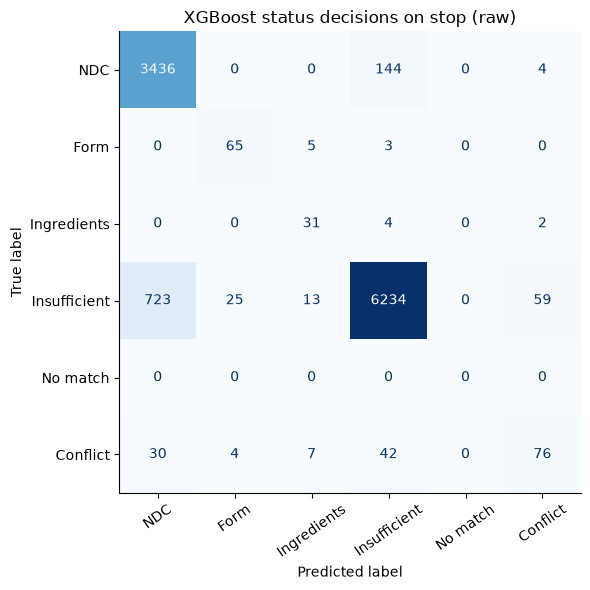

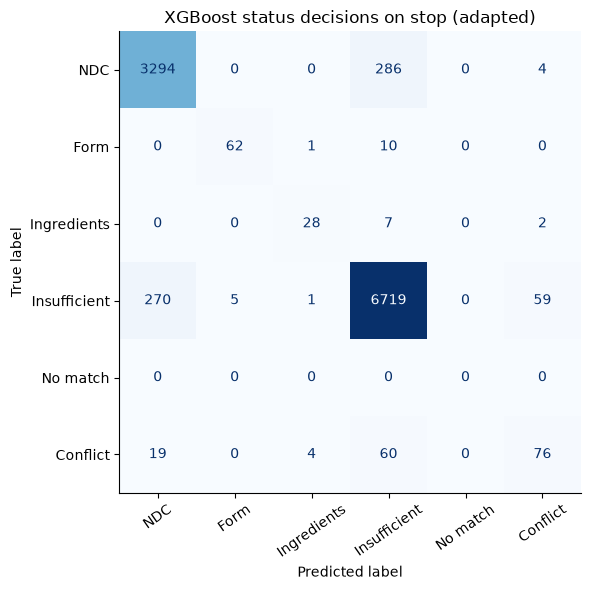

,metric,numerator,denominator,value
0,valid_output_rate,3352,3352,1.000000
1,joint_case_accuracy,3101,3352,0.925119
2,ingredient_set_accuracy,1179,1274,0.925432
3,comparison_accuracy,67,69,0.971014
4,abstention_accuracy,2578,2668,0.966267
5,unique_ndc_accuracy,1158,1252,0.924920
6,full_formulation_accuracy,148,226,0.654867
7,ingredient_precision,1844,1931,0.954946
8,ingredient_recall,1844,1997,0.923385
9,ingredient_f1,3688,3928,0.938900


calibration raw model decisions {'status_accuracy': {'numerator': 3660, 'denominator': 3942, 'value': 0.928462709284627}, 'status_confusion': [[1202, 0, 0, 40, 0, 10], [0, 13, 3, 0, 0, 0], [0, 0, 6, 0, 0, 0], [197, 6, 3, 2439, 0, 17], [0, 0, 0, 0, 0, 0], [0, 0, 0, 6, 0, 0]], 'top_record_source_support': {'numerator': 1284, 'denominator': 1284, 'value': 1.0}, 'mixed_source_support_requests': 10, 'source_support': {'precision': {'numerator': 1234, 'denominator': 1365, 'value': 0.904029304029304}, 'recall': {'numerator': 1234, 'denominator': 1306, 'value': 0.9448698315467075}, 'f1': {'numerator': 2468, 'denominator': 2671, 'value': 0.9239985024335455}}, 'source_support_target': 'source assessment support rather than query intent', 'sufficiency': {'precision': {'numerator': 1211, 'denominator': 1342, 'value': 0.9023845007451565}, 'recall': {'numerator': 1211, 'denominator': 1274, 'value': 0.9505494505494505}, 'f1': {'numerator': 2422, 'denominator': 2616, 'value': 0.9258409785932722}}, 'fo

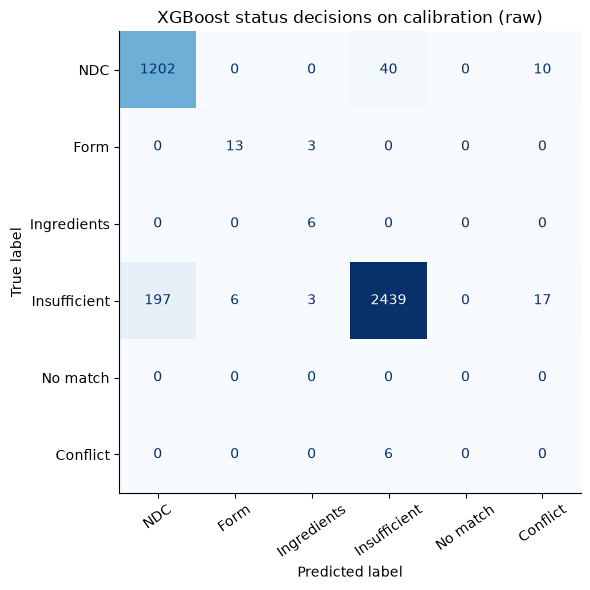

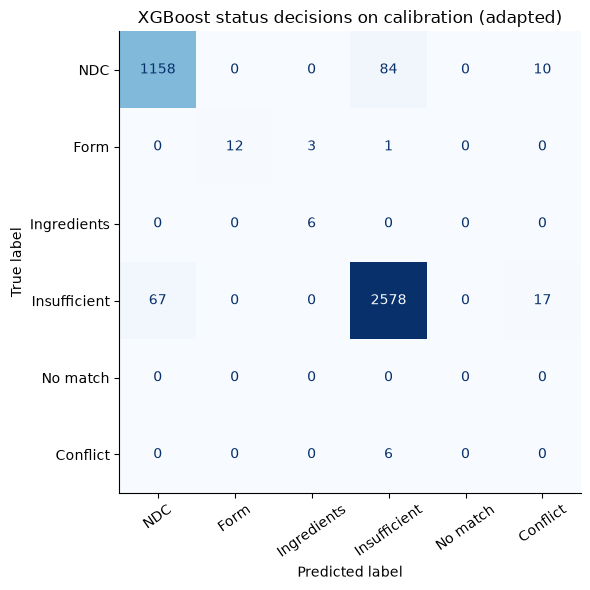

Development artifacts C:\Users\jibin\Documents\Academic\MSAI\8_AIH\HRP\otc-medication-llm-reliability\results\otc_models\xgboost_20261121T102526Z_4b76aa52\evaluations\development_d535889f


In [97]:
EVALUATION_ROOT = RUN_ROOT / "evaluations" / ("development_" + uuid.uuid4().hex[:8])
EVALUATION_ROOT.mkdir(parents=True, exist_ok=False)
dump_json(EVALUATION_ROOT / "thresholds.json", thresholds)
all_decisions, validation_reports, validation_predictions = {}, {}, {}
inference_start = time.perf_counter()
prediction_times = {}
for part in ("stop", "calibration"):
    prediction_start = time.perf_counter()
    decisions = cal_decisions if part == "calibration" else predict_heads(
        best_heads, items[part], matrices[part]["request"], matrices[part]["candidate"]
    )
    prediction_times[part] = cal_prediction_seconds if part == "calibration" else time.perf_counter() - prediction_start
    report, predictions, diagnostics = evaluate(used[part], decisions, resolver, thresholds)
    all_decisions[part] = decisions
    validation_reports[part] = report
    validation_predictions[part] = predictions
    dump_json(EVALUATION_ROOT / (part + "_metrics.json"), report)
    write_jsonl(EVALUATION_ROOT / (part + "_predictions.jsonl.gz"),
                ({"case_id": key, "output": value} for key, value in predictions.items()))
    write_jsonl(EVALUATION_ROOT / (part + "_adapter_changes.jsonl.gz"), diagnostics)
    display(pd.DataFrame([
        {"metric": key, **value} for key, value in report["overall"].items()
        if isinstance(value, dict) and "denominator" in value
    ]))
    print(part, "raw model decisions", report["raw"])
    print(part, "adapter interventions", {
        key: report[key] for key in ("adapter_status_changes", "adapter_form_changes",
                                    "adapter_intervened_requests", "adapter_reason_counts")
    })
    print(part, "raw pipeline joint accuracy", report["raw_pipeline"]["overall"]["joint_case_accuracy"])
    save_development_artifacts(EVALUATION_ROOT, part, used[part], decisions, predictions,
                               report, thresholds, prediction_times[part])
    regenerate_status_figures(EVALUATION_ROOT, part, "XGBoost status decisions on " + part)
inference_seconds = time.perf_counter() - inference_start

print("Development artifacts", EVALUATION_ROOT)


## 7.2 Check outputs and inspect features

Validate the final JSON structure and executable semantics. Feature importance helps describe the status head but does not establish causality.


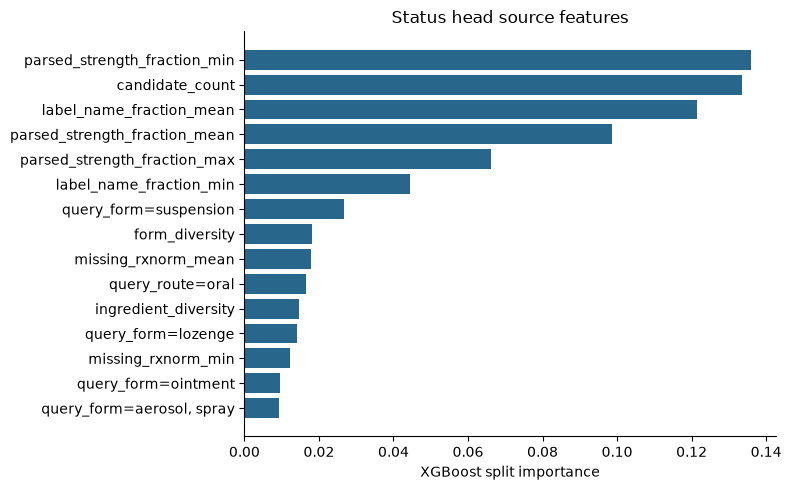

Development schema checks passed
Warm request predictions per second 22177.89994443279


In [98]:
# Validate both the structural schema and executable semantics on development outputs
schema = json.loads((CHALLENGE_ROOT / "output_schema.json").read_text(encoding="utf-8"))
for part in ("stop", "calibration"):
    for row in used[part]:
        output = validation_predictions[part][row["case_id"]]
        jsonschema.validate(output, schema)
        contract.parse_output(output, row["payload"])

def regenerate_feature_importance(root):
    root = Path(root)
    frame = pd.read_csv(root / "status_feature_importance.csv").sort_values("importance").tail(15)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(frame["feature"], frame["importance"], color="#28668c")
    ax.set(xlabel="XGBoost split importance", title="Status head source features")
    fig.tight_layout()
    fig.savefig(root / "status_feature_importance.png", dpi=300, bbox_inches="tight")
    plt.show()

if best_heads["status"].model is not None:
    atomic_csv(EVALUATION_ROOT / "status_feature_importance.csv", pd.DataFrame({
        "feature": request_encoder.get_feature_names_out(),
        "importance": best_heads["status"].model.feature_importances_}))
    regenerate_feature_importance(EVALUATION_ROOT)
# No deterministic teacher is invoked anywhere in model prediction
source_functions = [candidate_features, request_features, predict_heads, adapt_product, adapt_case]
for function in source_functions:
    if function is adapt_case:
        source = SHARED_SOURCE.split("def adapt_case", 1)[1].split("def flatten", 1)[0]
    else:
        source = inspect.getsource(function)
    if any(name in source for name in ("resolve_request(", "predict_common_evidence(", "assess_candidate(")):
        raise AssertionError("Source label code reached inference")
print("Development schema checks passed")
print("Warm request predictions per second", sum(len(items[p]) for p in prediction_times) / sum(prediction_times.values()))


# 8. Export a frozen tree model

Preserve models, encoders, feature definitions, thresholds, package versions and input fingerprints. Smoke exports remain ineligible for final evaluation.


## 8.1 Save the learned artifacts

The feature source is saved with the encoders so the inference representation can be reviewed.


In [99]:
import joblib

FEATURE_FUNCTIONS = [grams, jaccard, agreement, candidate_features, request_features, feature_rows]
FEATURE_SOURCE = "\n\n".join(inspect.getsource(function) for function in FEATURE_FUNCTIONS)

MODEL_ROOT = RUN_ROOT / "model"
MODEL_ROOT.mkdir(exist_ok=True)
model_already_exported = (MODEL_ROOT / "frozen.json").is_file()
if model_already_exported:
    saved_freeze = json.loads((MODEL_ROOT / "frozen.json").read_text(encoding="utf-8"))
    verify_files(MODEL_ROOT, saved_freeze["files"])
    saved_model_config = json.loads((MODEL_ROOT / "configuration.json").read_text(encoding="utf-8"))
    if saved_model_config["depth"] != best_depth or saved_model_config["thresholds"] != thresholds:
        raise ValueError("Existing frozen model selection differs")
    model_info = saved_model_config["head_models"]
else:
    model_info = {name: head.save(MODEL_ROOT, name) for name, head in best_heads.items()}
    atomic_joblib(MODEL_ROOT / "encoders.joblib", {"request": request_encoder, "candidate": candidate_encoder})
    (MODEL_ROOT / "feature_source.py").write_text(FEATURE_SOURCE, encoding="utf-8")
    dump_json(MODEL_ROOT / "features.json", {
        "request": request_encoder.get_feature_names_out().tolist(),
        "candidate": candidate_encoder.get_feature_names_out().tolist(),
        "missing_value": "negative sentinel for unknown comparison and explicit missing flags"
    })
    (MODEL_ROOT / "otc_shared.py").write_text(SHARED_SOURCE, encoding="utf-8")


## 8.2 Record the run and verify reload

Record missing classes for the actual fitted subset, including smoke subsets. Reload saved heads and compare development probabilities before accepting the export.


In [100]:
config = {
    "seed": SEED, "smoke_test": SMOKE_TEST, "full_training": RUN_FULL_TRAINING,
    "depth": best_depth, "trials": trials, "thresholds": thresholds,
    "training_seconds": training_seconds, "development_evaluation_seconds": inference_seconds,
    "development_prediction_seconds": sum(prediction_times.values()),
    "development_requests_per_second": sum(len(items[p]) for p in prediction_times) / sum(prediction_times.values()),
    "training_cases": len(used["train"]), "training_requests": len(items["train"]),
    "stop_cases": len(used["stop"]), "calibration_cases": len(used["calibration"]),
    "head_models": model_info,
    "head_semantics": {"candidate": "source support rather than query intent"},
    "dataset_unsupported_statuses": audit["unsupported_statuses"],
    "unsupported_statuses": [name for index, name in enumerate(STATUS)
                             if index not in best_heads["status"].classes],
    "constant_heads": [name for name, info in model_info.items() if info["constant"]],
    "packages": {name: metadata.version(name) for name in required},
    "python": sys.version, "source_hashes": audit["source_hashes"],
    "shared_code_sha256": sha_file(MODEL_ROOT / "otc_shared.py"),
    "scoring_contract": SCORING_CONTRACT_VERSION,
    "benchmark_contract": contract.VERSION
}
if not model_already_exported:
    dump_json(MODEL_ROOT / "configuration.json", config)
    (MODEL_ROOT / "requirements.txt").write_text(
        "\n".join(name + "==" + metadata.version(name) for name in required) + "\n", encoding="utf-8"
    )
    model_files = sorted(p for p in MODEL_ROOT.iterdir() if p.is_file())
    frozen = {
        "complete_training": not SMOKE_TEST and RUN_FULL_TRAINING,
        "configuration_sha256": sha_file(MODEL_ROOT / "configuration.json"),
        "files": {p.name: sha_file(p) for p in model_files},
        "model_bytes": sum(p.stat().st_size for p in model_files),
        "frozen_at_utc": datetime.now(timezone.utc).isoformat(),
        "challenge_used_for_training_or_calibration": False
    }
    dump_json(MODEL_ROOT / "frozen.json", frozen)
else:
    config, frozen = saved_model_config, saved_freeze
# Reload the actual saved models and confirm equal development probabilities
loaded_heads = {name: TreeHead.load(MODEL_ROOT, info) for name, info in model_info.items()}
saved_decisions = predict_heads(loaded_heads, items["calibration"],
                               matrices["calibration"]["request"], matrices["calibration"]["candidate"])
for a, b in zip(cal_decisions, saved_decisions):
    if not np.allclose(a["status"], b["status"]):
        raise RuntimeError("Exported model prediction mismatch")
print("Model saved", MODEL_ROOT)
print("Model bytes", frozen["model_bytes"])


Model saved C:\Users\jibin\Documents\Academic\MSAI\8_AIH\HRP\otc-medication-llm-reliability\results\otc_models\xgboost_20261121T102526Z_4b76aa52\model
Model bytes 10793331


# 9. Export the Colab dataset bundle

The bundle exports every approved training and development case even after a small tree smoke run. It includes source-only challenge inputs and the exact shared code and frozen scorer, with no final references or saved Gemma responses.


## 9.1 Write source code and permitted cases

Preserve source records and labels in separate fields. Challenge rows contain only case IDs and source payloads.


In [101]:
def write_bundle_sources():
    # Export modules verbatim so both environments use one scoring implementation
    frozen_dir = BUNDLE_ROOT / "frozen/hrp"
    frozen_dir.mkdir(parents=True, exist_ok=True)
    for name in ("__init__.py", "data_cleaning.py", "challenge_evaluation.py", "challenge_scoring_v3.py"):
        shutil.copyfile(ROOT / "src/hrp" / name, frozen_dir / name)
    (BUNDLE_ROOT / "otc_shared.py").write_text(SHARED_SOURCE, encoding="utf-8")
    shutil.copyfile(CHALLENGE_ROOT / "output_schema.json", BUNDLE_ROOT / "output_schema.json")
    atomic_jsonl(BUNDLE_ROOT / "ingredient_identities.jsonl.gz", identity_entries)
    dump_json(BUNDLE_ROOT / "bundle_config.json", {
        "seed": SEED, "label_source": "exact-version sources for approved queries",
        "extra_training_cases": 0, "source_preparation_seconds": audit["preparation_seconds"]
    })

def write_bundle_cases():
    clean_meta = {"families", "task", "category", "case_type", "split", "label_source"}
    for part, rows in data.items():
        export_rows = (
            {
                "case_id": row["case_id"], "payload": row["payload"],
                "target": row["target"], "candidate_labels": row["candidate_labels"],
                "meta": {key: value for key, value in row["meta"].items() if key in clean_meta}
            }
            for row in rows
        )
        if not (BUNDLE_ROOT / (part + ".jsonl.gz")).is_file():
            atomic_jsonl(BUNDLE_ROOT / (part + ".jsonl.gz"), export_rows)
    challenge_rows = [
        {"case_id": row["case_id"], "payload": row["payload"]}
        for row in read_jsonl(CHALLENGE_ROOT / "common_evidence.PRIVATE.jsonl")
    ]
    for row in challenge_rows:
        if set(row) != {"case_id", "payload"}:
            raise ValueError("Final source bundle contains extra fields")
        check_payload(row["payload"])
    atomic_jsonl(BUNDLE_ROOT / "challenge_inputs.jsonl.gz", challenge_rows)
    return challenge_rows


## 9.2 Write split and schema metadata

The manifest records family exclusions, data hashes, encoding details and the meaning of source-support labels.


In [102]:
def write_bundle_metadata(challenge_rows):
    split_manifest = {
        "seed": SEED,
        "training_policy": "Frozen allowlist only with every quarantined family removed",
        "development_policy": "All challenge families removed with connected family components split 70 to 30",
        "case_ids": {part: [r["case_id"] for r in rows] for part, rows in data.items()},
        "families": {part: sorted({g for r in rows for g in r["meta"]["families"]})
                     for part, rows in data.items()},
        "excluded_validation_case_ids": sorted({r["case_id"] for r in raw_dev} - {r["case_id"] for r in dev_rows}),
        "challenge_case_ids": sorted(challenge_ids),
        "challenge_family_ids": sorted(challenge_groups),
        "quarantined_training_family_ids": sorted(blocked),
        "training_semantic_keys_sha256": sha_value(sorted(train_keys)),
        "development_semantic_keys_sha256": sha_value(sorted(dev_keys)),
        "semantic_overlap_count": 0, "family_overlap_count": 0
    }
    dump_json(BUNDLE_ROOT / "split_manifest.json", split_manifest)
    dump_json(BUNDLE_ROOT / "encoding.json", {
        "text_encoding": "UTF-8 bytes plus one with zero reserved for padding",
        "vocabulary_size": 257, "normalization": "NFKC and casefold with normalized whitespace",
        "query_fields": ["name", "dosage_form", "route", "native_strengths", "product_ndc"],
        "candidate_fields": ["names", "ingredients", "strengths", "form_route", "identifiers", "source_text"],
        "candidate_truncation": False, "text_chunk_bytes": 160
    })
    dump_json(BUNDLE_ROOT / "dataset_schema.json", {
        "version": 1, "statuses": STATUS, "benchmark_contract": contract.VERSION,
        "scoring_contract": SCORING_CONTRACT_VERSION,
        "training_row_fields": ["case_id", "payload", "target", "candidate_labels", "meta"],
        "inference_row_fields": ["case_id", "payload"],
        "label_policy": "Approved queries relabelled from exact-version source assessments",
        "unsupported_training_statuses": audit["unsupported_statuses"],
        "case_counts": {part: len(rows) for part, rows in data.items()},
        "split_data_sha256": {part: sha_file(BUNDLE_ROOT / (part + ".jsonl.gz")) for part in data},
        "identity_mapping_sha256": sha_file(BUNDLE_ROOT / "ingredient_identities.jsonl.gz"),
        "output_schema_sha256": sha_file(BUNDLE_ROOT / "output_schema.json"),
        "challenge_count": 230,
        "challenge_payload_sha256": sha_value(challenge_rows),
        "features_receive": "payload only",
        "candidate_labels_semantics": "Source support rather than query intent"
    })
    # Paths and source hashes are provenance and never become model features
    dump_json(BUNDLE_ROOT / "preparation_report.json", audit)


## 9.3 Create the upload folder

Copy the entire prepared_data folder printed below to MyDrive/HRP_OTC/prepared_data. The checksum manifest covers all exported files.


In [103]:
def export_bundle():
    manifest_path = BUNDLE_ROOT / "manifest.json"
    if manifest_path.is_file():
        saved = json.loads(manifest_path.read_text(encoding="utf-8"))
        verify_files(BUNDLE_ROOT, saved["files"])
        print("Reused verified Google Drive bundle", BUNDLE_ROOT)
        return saved
    write_bundle_sources()
    challenge_rows = write_bundle_cases()
    write_bundle_metadata(challenge_rows)
    files = sorted(p for p in BUNDLE_ROOT.rglob("*") if p.is_file())
    manifest = {
        "version": 1, "files": {p.relative_to(BUNDLE_ROOT).as_posix(): sha_file(p) for p in files},
        "challenge_references_included": False, "saved_model_responses_included": False,
        "training_case_count": len(data["train"]),
        "development_case_count": len(data["stop"]) + len(data["calibration"])
    }
    dump_json(BUNDLE_ROOT / "manifest.json", manifest)
    print("Copy this whole folder to Google Drive", BUNDLE_ROOT)
    display(pd.DataFrame([{
        "file": p.relative_to(BUNDLE_ROOT).as_posix(),
        "bytes": p.stat().st_size, "sha256": sha_file(p)
    } for p in sorted(BUNDLE_ROOT.rglob("*")) if p.is_file()]))
    return manifest

if EXPORT_BUNDLE:
    bundle_manifest = export_bundle()
else:
    print("Bundle export is disabled")


Copy this whole folder to Google Drive C:\Users\jibin\Documents\Academic\MSAI\8_AIH\HRP\otc-medication-llm-reliability\results\otc_models\xgboost_20261121T102526Z_4b76aa52\prepared_data


,file,bytes,sha256
0,bundle_config.json,165,0afe81a5b93f3ee5cd00969f725dbc21819ba59f4fc986...
1,calibration.jsonl.gz,1436826,c5b09e98e9b5ad6f3d727317c851d43a4928eceb3902c6...
2,challenge_inputs.jsonl.gz,141759,ea7fbd3cc11429474fff83d98b684e8e7e6bb8ea6672ce...
3,dataset_schema.json,1459,27dcd8c34c1d5d34d48dc3ba7871ea9d6d2f439a567106...
4,encoding.json,494,95575d0cd231894d2c31de8cd3d22edbb0bb8e38070cd8...
5,frozen/hrp/__init__.py,129,2fcb176e7151f443956e2e41b83e0bbe66243ce87f27e6...
6,frozen/hrp/challenge_evaluation.py,36024,040164b712f8a3347008406c8f3d3241b9f05172ba7913...
7,frozen/hrp/challenge_scoring_v3.py,2334,70e76f011d903b9181e4bebbda0b6ad2c77adf3a7b0498...
8,frozen/hrp/data_cleaning.py,14764,39bf96c2b5ad7645522f255c65581662f7622756ae8e15...
9,ingredient_identities.jsonl.gz,506067,2dbd9177191ce8461d9583b5f1993e06f63a4012119a3b...


# 11 Interpret the supervision carefully

The original references contain no NO_MATCH or SOURCE_CONFLICT examples. Empty retrieval sets use a documented NO_MATCH rule. Source conflict is learned only if exact-source preparation produces observed examples. Otherwise its class remains unsupported. No synthetic queries are added.

The retrieval filter already narrows most requests to one record. Source-support scores therefore assess the reliability of those records, not the ability to infer a user's intended medicine. Source derived labels and deterministic constraints share a policy with the comparator, which limits claims about independent knowledge.


# 12. Implementation reference

The fitting calls follow the [XGBoost Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html). The frozen repository modules remain the authority for source identity and scoring.
